# BT4012 — Bitcoin Transaction Fraud Detection: Baseline V1

**Purpose:** Establish a reproducible, chronological-validation baseline before engineering graph features or tuning advanced models.

**Models:** Balanced Logistic Regression and LightGBM. **Evaluation:** ROC-AUC (competition metric) and average precision / PR-AUC. This notebook does **not** look at test labels or tune using the public leaderboard.

Place `train.csv`, `test.csv`, `txs_edgelist.csv`, and `sample_submission.csv` in the same folder as this notebook, or change `DATA_DIR`.


In [3]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from lightgbm import LGBMClassifier, early_stopping

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
DATA_DIR = Path(".")
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
edges = pd.read_csv(DATA_DIR / "txs_edgelist.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")
FEATURES = [f"feat_{i}" for i in range(1, 166)]
print("Shapes:", train.shape, test.shape, edges.shape, sample_submission.shape)
assert set(FEATURES).issubset(train.columns)
assert set(FEATURES).issubset(test.columns)
assert train["txId"].is_unique and test["txId"].is_unique
assert not set(train.txId).intersection(set(test.txId))
assert set(train.label.dropna().unique()).issubset({0, 1})
assert len(test) == len(sample_submission)
assert {"index", "target"}.issubset(sample_submission.columns)
assert test["index"].equals(sample_submission["index"])


Shapes: (141772, 168) (15329, 168) (234355, 2) (15329, 2)


## 1. Audit: labels, time steps, feature-level missingness

In [4]:
print("Label counts (NaN means unknown, not licit):")
print(train.label.value_counts(dropna=False))
print("\nFeature NaNs:", int(train[FEATURES].isna().sum().sum()))
print("Constant feature count:", int((train[FEATURES].nunique(dropna=False) <= 1).sum()))
print("Train steps:", train.time_step.min(), "-", train.time_step.max())
print("Test steps:", test.time_step.min(), "-", test.time_step.max())
print("\nLabels by time step:")
by_step = train.groupby("time_step").label.agg(
    labelled="count", illicit="sum"
)
by_step["illicit_rate"] = by_step.illicit / by_step.labelled
display(by_step)


Label counts (NaN means unknown, not licit):
label
NaN    110537
0.0     27591
1.0      3644
Name: count, dtype: int64

Feature NaNs: 0
Constant feature count: 0
Train steps: 1 - 35
Test steps: 36 - 49

Labels by time step:


,labelled,illicit,illicit_rate
time_step,,,
1,2147,17.0,0.007918
2,1117,18.0,0.016115
3,1279,11.0,0.008600
4,1440,30.0,0.020833
5,1882,8.0,0.004251
6,485,5.0,0.010309
7,1203,102.0,0.084788
8,1165,67.0,0.057511
9,778,248.0,0.318766


## 2. Chronological validation

Two pre-declared future holdouts:
- **Long horizon:** fit time steps 1–21, validate 22–35.
- **Short horizon:** fit time steps 1–28, validate 29–35.

Unknown-labelled rows are not used to fit supervised classifiers. We intentionally exclude `txId`, `index`, `label`, and `time_step` from baseline input features. `time_step` is used only for splitting; including it as a predictor can be tested later with proper out-of-time validation.

**Note:** These folds overlap; do not average them as if they were independent. The final hidden test spans 14 future steps (36–49), making the long-horizon comparison especially important.


In [5]:
labeled = train.loc[train.label.notna()].copy()
FOLDS = [
    ("long_22_35", 21, 35),
    ("short_29_35", 28, 35),
]
def get_fold(cutoff, end):
    tr = labeled.loc[labeled.time_step <= cutoff]
    va = labeled.loc[(labeled.time_step > cutoff) & (labeled.time_step <= end)]
    assert len(tr) and len(va)
    assert tr.time_step.max() < va.time_step.min()
    assert tr.label.nunique() == 2 and va.label.nunique() == 2
    return tr, va

for name, cutoff, end in FOLDS:
    a,b = get_fold(cutoff,end)
    print(name, "train", len(a), "valid", len(b),
          "valid illicit rate", round(b.label.mean(),4))


long_22_35 train 19530 valid 11705 valid illicit rate 0.1515
short_29_35 train 25207 valid 6028 valid illicit rate 0.1828


## 3. Train baseline models and record metrics

In [6]:
def fit_models(fold_name, cutoff, end):
    tr, va = get_fold(cutoff, end)
    x_train = tr[FEATURES].astype("float32")
    x_valid = va[FEATURES].astype("float32")
    y_train = tr.label.astype(int)
    y_valid = va.label.astype(int)

    models = {
        "Logistic Regression": make_pipeline(
            StandardScaler(),
            LogisticRegression(
                max_iter=1500, class_weight="balanced",
                solver="lbfgs", random_state=SEED
            )
        ),
        "LightGBM": LGBMClassifier(
            n_estimators=1000,
            learning_rate=0.035,
            num_leaves=15,
            min_child_samples=40,
            colsample_bytree=0.85,
            subsample=0.85,
            subsample_freq=1,
            reg_lambda=3.0,
            random_state=SEED,
            n_jobs=4,
            verbosity=-1,
        )
    }
    records = []
    for model_name, model in models.items():
        if model_name == "LightGBM":
            model.fit(
                x_train, y_train,
                eval_set=[(x_valid, y_valid)],
                eval_metric="auc",
                callbacks=[early_stopping(60, verbose=False)]
            )
        else:
            model.fit(x_train,y_train)
        p = model.predict_proba(x_valid)[:,1]
        records.append({
            "fold":fold_name, "model":model_name,
            "train_rows":len(tr), "valid_rows":len(va),
            "valid_illicit_rate":float(y_valid.mean()),
            "roc_auc":roc_auc_score(y_valid,p),
            "average_precision":average_precision_score(y_valid,p),
            "best_iteration":getattr(model,"best_iteration_",None)
        })
    return records

records = []
for name, cutoff, end in FOLDS:
    records.extend(fit_models(name, cutoff, end))
results = pd.DataFrame(records)
display(results.round(5))
results.to_csv("baseline_validation_results.csv",index=False)


/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,fold,model,train_rows,valid_rows,valid_illicit_rate,roc_auc,average_precision,best_iteration
0,long_22_35,Logistic Regression,19530,11705,0.15147,0.82175,0.45280,NaN
1,long_22_35,LightGBM,19530,11705,0.15147,0.82777,0.74526,3.0
2,short_29_35,Logistic Regression,25207,6028,0.18281,0.89662,0.56302,NaN
3,short_29_35,LightGBM,25207,6028,0.18281,0.99611,0.98417,424.0


## 4. Interpretation and safeguards

- **ROC-AUC** drives competition ranking; average precision is an additional fraud-focused diagnostic.
- **Never** use unknown labels as `0`.
- This baseline does not incorporate edges, unlabeled-node representations, or a GNN.
- A large difference across folds may reflect regime/label variation, dataset-specific artifacts, or instability. Investigate before model selection.
- LightGBM early stopping uses the validation fold, so these scores guide model development rather than constituting a fully untouched final estimate. Use additional rolling temporal folds and final holdout discipline before claiming generalisation.
- Record every experiment (features, hyperparameters, validation horizon, seed), and do not use public leaderboard feedback as a substitute for local validation.

**Next experiment:** a more detailed time-step analysis plus graph-degree and directional-neighbour features, using the same folds.


In [7]:

import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

df = train.dropna(subset=["label"]).copy()
features = [f"feat_{i}" for i in range(1, 166)]

folds = {
    "long_22_35": (21, 22, 35),
    "short_29_35": (28, 29, 35),
}

for name, (train_end, val_start, val_end) in folds.items():
    tr = df[df["time_step"] <= train_end]
    va = df[df["time_step"].between(val_start, val_end)]

    model = lgb.LGBMClassifier(
        n_estimators=1500,
        learning_rate=0.03,
        num_leaves=31,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )

    model.fit(
        tr[features], tr["label"].astype(int),
        eval_set=[(va[features], va["label"].astype(int))],
        eval_metric="auc",
        callbacks=[lgb.early_stopping(100, verbose=False)]
    )

    pred = model.predict_proba(va[features])[:, 1]

    results = va[["time_step", "label"]].copy()
    results["prediction"] = pred

    rows = []
    for step, group in results.groupby("time_step"):
        y = group["label"].astype(int)
        rows.append({
            "time_step": step,
            "n": len(group),
            "illicit": int(y.sum()),
            "illicit_rate": round(y.mean(), 4),
            "roc_auc": (
                round(roc_auc_score(y, group["prediction"]), 5)
                if y.nunique() == 2 else np.nan
            ),
        })

    print(f"\n{'='*60}")
    print(name)
    print("Best iteration:", model.best_iteration_)
    print("Overall ROC-AUC:",
          round(roc_auc_score(va["label"], pred), 5))
    print("Overall PR-AUC:",
          round(average_precision_score(va["label"], pred), 5))
    print("\nROC-AUC by time step:")
    print(pd.DataFrame(rows).to_string(index=False))

    importance = pd.DataFrame({
        "feature": features,
        "importance": model.feature_importances_
    }).sort_values("importance", ascending=False)

    print("\nTop 15 features:")
    print(importance.head(15).to_string(index=False))


/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)



long_22_35
Best iteration: 73
Overall ROC-AUC: 0.88061
Overall PR-AUC: 0.78208

ROC-AUC by time step:
 time_step    n  illicit  illicit_rate  roc_auc
        22 1763      158        0.0896  0.99758
        23 1187       53        0.0447  0.94391
        24 1126      137        0.1217  0.74410
        25  594      118        0.1987  0.99922
        26  517       96        0.1857  0.90765
        27  206       24        0.1165  0.99794
        28  284       85        0.2993  0.99982
        29 1174      329        0.2802  0.72484
        30  524       83        0.1584  0.97508
        31  710      106        0.1493  0.72440
        32 1323      342        0.2585  0.79802
        33  441       23        0.0522  0.97743
        34  515       37        0.0718  0.99350
        35 1341      182        0.1357  0.99016

Top 15 features:
 feature  importance
  feat_2         346
 feat_53         101
feat_163          70
 feat_90          68
 feat_47          64
feat_100          62
 feat_58    

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)



short_29_35
Best iteration: 359
Overall ROC-AUC: 0.99669
Overall PR-AUC: 0.98785

ROC-AUC by time step:
 time_step    n  illicit  illicit_rate  roc_auc
        29 1174      329        0.2802  0.99684
        30  524       83        0.1584  0.99336
        31  710      106        0.1493  0.98832
        32 1323      342        0.2585  0.99886
        33  441       23        0.0522  0.99646
        34  515       37        0.0718  0.99887
        35 1341      182        0.1357  0.99599

Top 15 features:
 feature  importance
  feat_2         991
 feat_53         456
 feat_52         277
 feat_58         248
feat_138         223
feat_142         212
 feat_16         209
  feat_8         200
feat_125         197
 feat_59         193
feat_106         193
  feat_5         191
  feat_3         175
 feat_89         169
feat_100         167


In [8]:

import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

# Use your existing train dataframe
df = train.copy()
df["label"] = pd.to_numeric(df["label"], errors="coerce")
df = df.dropna(subset=["label"]).copy()
df["label"] = df["label"].astype(int)

features = [f"feat_{i}" for i in range(1, 166)]

# Train -> Tune -> Untouched evaluation
folds = {
    "earlier": {
        "train_end": 14,
        "tune_start": 15,
        "tune_end": 21,
        "eval_start": 22,
        "eval_end": 28,
    },
    "later": {
        "train_end": 21,
        "tune_start": 22,
        "tune_end": 28,
        "eval_start": 29,
        "eval_end": 35,
    },
}

experiments = {
    "Full features": features,
    "Without feat_2": [f for f in features if f != "feat_2"],
    "Recent 12 steps": features,
    "With time_step": features + ["time_step"],
}

summary = []
step_results = []
importance_results = []

for fold_name, f in folds.items():

    train_mask = df["time_step"] <= f["train_end"]
    tune_mask = df["time_step"].between(
        f["tune_start"], f["tune_end"]
    )
    eval_mask = df["time_step"].between(
        f["eval_start"], f["eval_end"]
    )

    for experiment, cols in experiments.items():

        if experiment == "Recent 12 steps":
            start = max(1, f["train_end"] - 11)
            tr = df[
                df["time_step"].between(start, f["train_end"])
            ].copy()
        else:
            tr = df[train_mask].copy()

        tune = df[tune_mask].copy()
        ev = df[eval_mask].copy()

        model = lgb.LGBMClassifier(
            n_estimators=1500,
            learning_rate=0.03,
            num_leaves=31,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        )

        # Tune on intermediate time steps ONLY
        model.fit(
            tr[cols],
            tr["label"],
            eval_X=tune[cols],
            eval_y=tune["label"],
            eval_metric="auc",
            callbacks=[
                lgb.early_stopping(100, verbose=False)
            ]
        )

        # Evaluate on untouched future periods
        pred = model.predict_proba(ev[cols])[:, 1]

        auc = roc_auc_score(ev["label"], pred)
        ap = average_precision_score(ev["label"], pred)

        summary.append({
            "fold": fold_name,
            "experiment": experiment,
            "train_rows": len(tr),
            "tune_rows": len(tune),
            "eval_rows": len(ev),
            "best_iteration": model.best_iteration_,
            "roc_auc": auc,
            "pr_auc": ap
        })

        # Per-time-step evaluation
        for step in sorted(ev["time_step"].unique()):
            mask = ev["time_step"].to_numpy() == step
            y_step = ev.loc[
                ev["time_step"] == step, "label"
            ]

            if y_step.nunique() == 2:
                step_auc = roc_auc_score(
                    y_step, pred[mask]
                )
            else:
                step_auc = np.nan

            step_results.append({
                "fold": fold_name,
                "experiment": experiment,
                "time_step": step,
                "roc_auc": step_auc,
                "n": len(y_step),
                "illicit": int(y_step.sum())
            })

        # Feature importance
        for col, imp in zip(
            cols, model.feature_importances_
        ):
            importance_results.append({
                "fold": fold_name,
                "experiment": experiment,
                "feature": col,
                "importance": imp
            })

        print(
            f"{fold_name} | {experiment}: "
            f"AUC={auc:.5f}, AP={ap:.5f}, "
            f"best_iteration={model.best_iteration_}"
        )

summary_df = pd.DataFrame(summary)
step_df = pd.DataFrame(step_results)
importance_df = pd.DataFrame(importance_results)

print("\n=== OVERALL RESULTS ===")
print(summary_df.to_string(index=False))

print("\n=== AUC BY TIME STEP ===")
print(
    step_df.pivot_table(
        index=["fold", "time_step"],
        columns="experiment",
        values="roc_auc"
    ).round(5).to_string()
)

print("\n=== TOP 15 FEATURES: LATER FOLD / FULL MODEL ===")
print(
    importance_df[
        (importance_df["fold"] == "later") &
        (importance_df["experiment"] == "Full features")
    ]
    .sort_values("importance", ascending=False)
    .head(15)
    .to_string(index=False)
)

# Save all results
summary_df.to_csv("diagnostic_v3_summary.csv", index=False)
step_df.to_csv("diagnostic_v3_by_step.csv", index=False)
importance_df.to_csv("diagnostic_v3_importance.csv", index=False)

print("\nDiagnostic V3 complete!")


earlier | Full features: AUC=0.87571, AP=0.80504, best_iteration=64
earlier | Without feat_2: AUC=0.92852, AP=0.82832, best_iteration=234
earlier | Recent 12 steps: AUC=0.87108, AP=0.81834, best_iteration=103
earlier | With time_step: AUC=0.88475, AP=0.80707, best_iteration=74
later | Full features: AUC=0.80519, AP=0.73190, best_iteration=87
later | Without feat_2: AUC=0.80888, AP=0.75769, best_iteration=89
later | Recent 12 steps: AUC=0.78700, AP=0.54677, best_iteration=101
later | With time_step: AUC=0.80519, AP=0.73190, best_iteration=87

=== OVERALL RESULTS ===
   fold      experiment  train_rows  tune_rows  eval_rows  best_iteration  roc_auc   pr_auc
earlier   Full features       14896       4634       5677              64 0.875713 0.805035
earlier  Without feat_2       14896       4634       5677             234 0.928518 0.828320
earlier Recent 12 steps       11632       4634       5677             103 0.871084 0.818337
earlier  With time_step       14896       4634       5677   

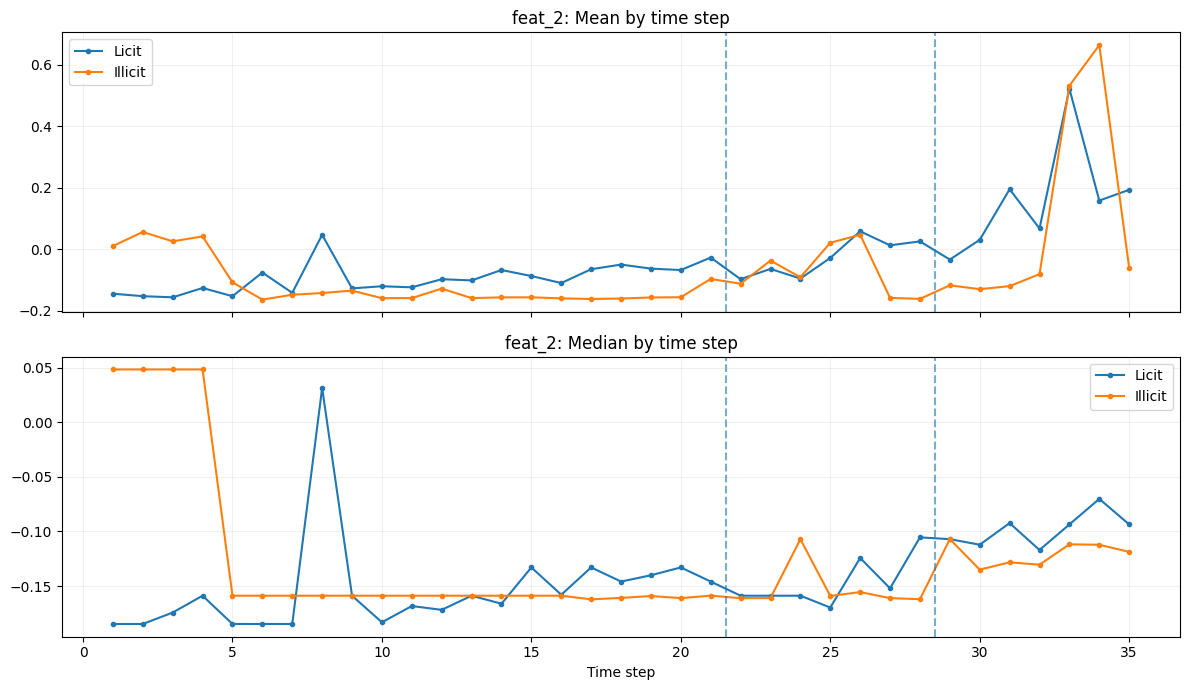

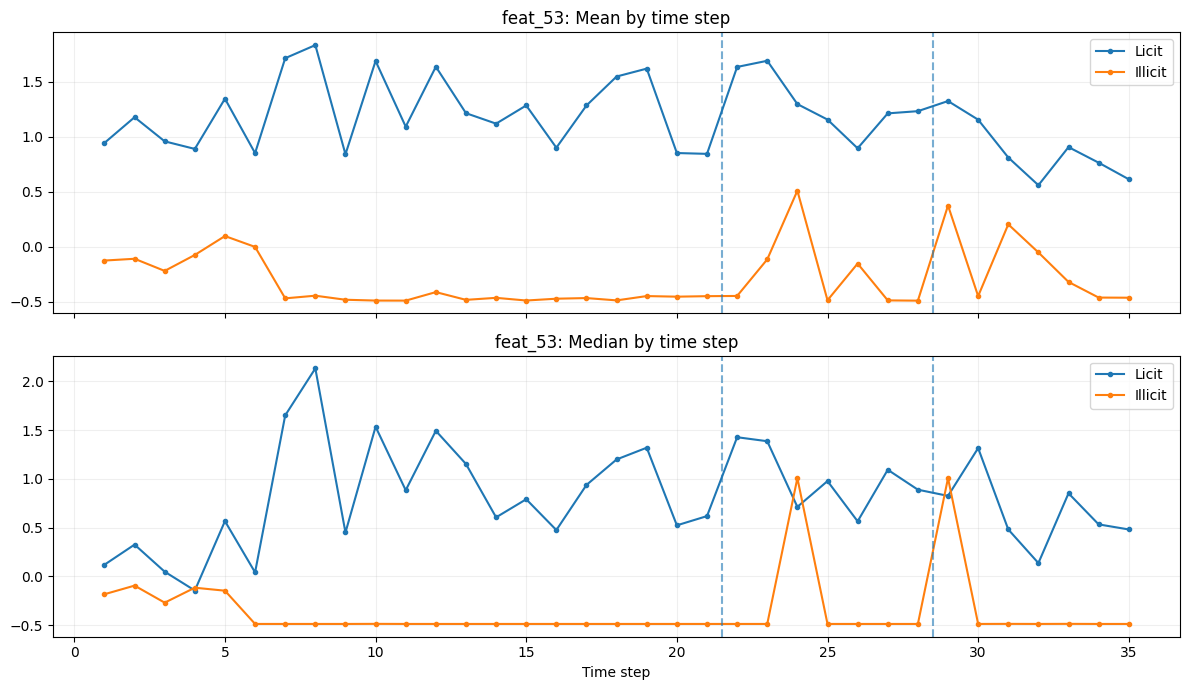

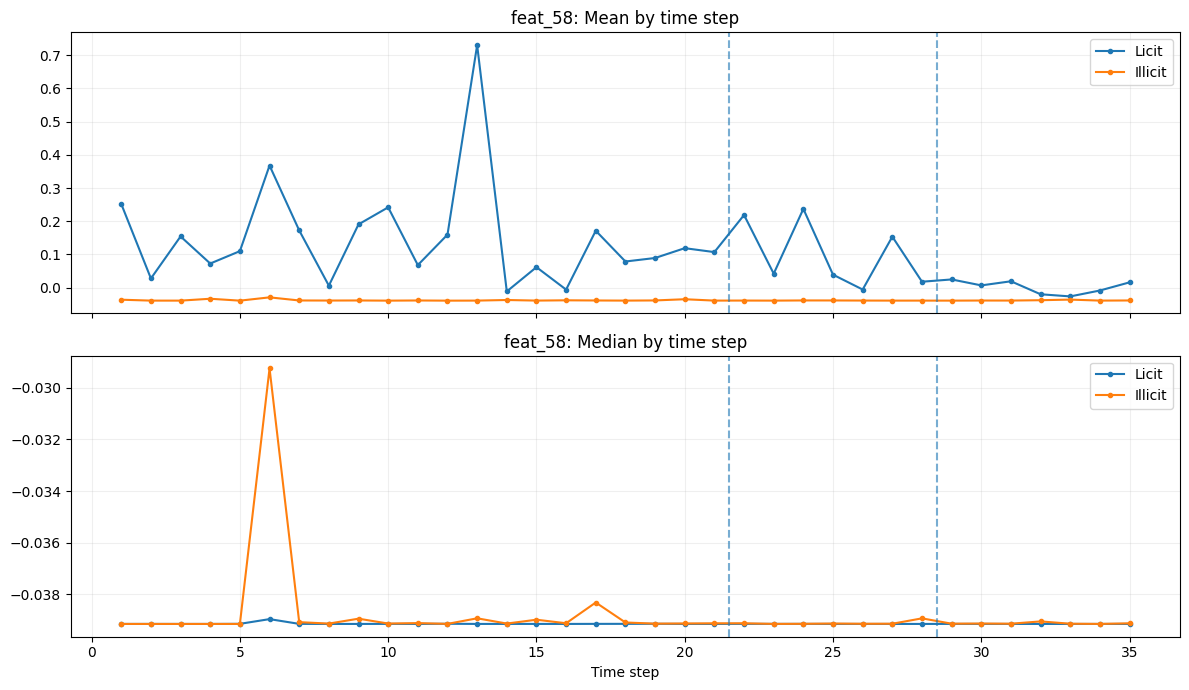


Single-feature discrimination by time step:
feature    feat_2  feat_53  feat_58
time_step                          
22         0.5695   0.9367   0.7331
23         0.5110   0.8695   0.5044
24         0.6054   0.6068   0.5293
25         0.6072   0.9751   0.7654
26         0.6742   0.8368   0.7403
27         0.8622   0.9821   0.8565
28         0.7635   0.9816   0.7979
29         0.5660   0.6781   0.5941
30         0.5750   0.9497   0.7352
31         0.6926   0.6991   0.7735
32         0.7714   0.6260   0.8876
33         0.8034   0.8916   0.8493
34         0.7872   0.9444   0.7876
35         0.9074   0.9178   0.8281

Feature direction:
feature      feat_2   feat_53   feat_58
time_step                              
22         negative  negative  positive
23         negative  negative  negative
24         positive  negative  positive
25         positive  negative  positive
26         negative  negative  positive
27         negative  negative  positive
28         negative  negative  positive

In [9]:

import pandas as pd
import matplotlib.pyplot as plt

df = train.dropna(subset=["label"]).copy()
df["label"] = df["label"].astype(int)

investigate = ["feat_2", "feat_53", "feat_58"]

for feature in investigate:
    fig, axes = plt.subplots(2, 1, figsize=(12, 7),
                             sharex=True)

    for cls, label in [(0, "Licit"), (1, "Illicit")]:
        subset = df[df["label"] == cls]
        grouped = subset.groupby("time_step")[feature]

        axes[0].plot(
            grouped.mean().index,
            grouped.mean().values,
            marker="o",
            markersize=3,
            label=label
        )

        axes[1].plot(
            grouped.median().index,
            grouped.median().values,
            marker="o",
            markersize=3,
            label=label
        )

    axes[0].set_title(f"{feature}: Mean by time step")
    axes[1].set_title(f"{feature}: Median by time step")

    for ax in axes:
        ax.axvline(21.5, linestyle="--", alpha=0.6)
        ax.axvline(28.5, linestyle="--", alpha=0.6)
        ax.legend()
        ax.grid(alpha=0.2)

    axes[1].set_xlabel("Time step")
    plt.tight_layout()
    plt.show()

# Quantify separability by feature in difficult periods
from sklearn.metrics import roc_auc_score

rows = []

for step in range(22, 36):
    subset = df[df["time_step"] == step]
    y = subset["label"]

    for feature in investigate:
        auc = roc_auc_score(y, subset[feature])
        rows.append({
            "time_step": step,
            "feature": feature,
            "single_feature_auc": max(auc, 1 - auc),
            "direction": "positive" if auc >= 0.5
                         else "negative"
        })

drift_table = pd.DataFrame(rows)

print("\nSingle-feature discrimination by time step:")
print(
    drift_table.pivot(
        index="time_step",
        columns="feature",
        values="single_feature_auc"
    ).round(4)
)

print("\nFeature direction:")
print(
    drift_table.pivot(
        index="time_step",
        columns="feature",
        values="direction"
    )
)


In [10]:

import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

df = train.dropna(subset=["label"]).copy()
df["label"] = df["label"].astype(int)

features = [f"feat_{i}" for i in range(1, 166)]
feature_sets = {
    "All features": features,
    "Without feat_2": [f for f in features if f != "feat_2"]
}

# Same untouched evaluation data in every experiment
ev = df[df["time_step"].between(29, 35)].copy()

results = []
step_results = []

for train_end in [21, 28]:
    tr = df[df["time_step"] <= train_end].copy()

    for feature_name, cols in feature_sets.items():
        for n_trees in [100, 300]:

            model = lgb.LGBMClassifier(
                n_estimators=n_trees,
                learning_rate=0.03,
                num_leaves=31,
                random_state=42,
                verbosity=-1,
                n_jobs=-1
            )

            model.fit(tr[cols], tr["label"])

            pred = model.predict_proba(ev[cols])[:, 1]

            auc = roc_auc_score(ev["label"], pred)
            ap = average_precision_score(ev["label"], pred)

            results.append({
                "train_end": train_end,
                "training_rows": len(tr),
                "features": feature_name,
                "trees": n_trees,
                "roc_auc": round(auc, 5),
                "pr_auc": round(ap, 5)
            })

            for step in range(29, 36):
                mask = ev["time_step"] == step
                step_results.append({
                    "train_end": train_end,
                    "features": feature_name,
                    "trees": n_trees,
                    "time_step": step,
                    "roc_auc": round(
                        roc_auc_score(
                            ev.loc[mask, "label"],
                            pred[mask.to_numpy()]
                        ), 5
                    )
                })

results_df = pd.DataFrame(results)
step_results_df = pd.DataFrame(step_results)

print("\n=== CONTROLLED COMPARISON ===")
print(results_df.to_string(index=False))

print("\n=== PER-STEP COMPARISON (300 TREES) ===")
print(
    step_results_df[
        step_results_df["trees"] == 300
    ].pivot_table(
        index="time_step",
        columns=["train_end", "features"],
        values="roc_auc"
    ).round(5).to_string()
)

results_df.to_csv("v5_results.csv", index=False)
step_results_df.to_csv("v5_by_step.csv", index=False)



=== CONTROLLED COMPARISON ===
 train_end  training_rows       features  trees  roc_auc  pr_auc
        21          19530   All features    100  0.85303 0.75139
        21          19530   All features    300  0.83918 0.76036
        21          19530 Without feat_2    100  0.80373 0.75566
        21          19530 Without feat_2    300  0.84697 0.77045
        28          25207   All features    100  0.99261 0.97401
        28          25207   All features    300  0.99629 0.98658
        28          25207 Without feat_2    100  0.99385 0.97664
        28          25207 Without feat_2    300  0.99723 0.99039

=== PER-STEP COMPARISON (300 TREES) ===
train_end           21                          28               
features  All features Without feat_2 All features Without feat_2
time_step                                                        
29             0.72374        0.72025      0.99607        0.99644
30             0.98831        0.99251      0.99320        0.99481
31           

In [12]:

# Create submission directly from test.csv
submission = pd.DataFrame({
    "index": test["index"],
    "target": pred
})

# Validate submission
assert len(submission) == len(test) == 15329
assert submission["target"].between(0, 1).all()
assert submission["target"].notna().all()

# Save submission
submission.to_csv("submission_lgbm_v1.csv", index=False)

print(submission.head())
print("Saved submission_lgbm_v1.csv")


   index    target
0      0  0.000749
1      1  0.001531
2      2  0.000469
3      3  0.000325
4      4  0.000107
Saved submission_lgbm_v1.csv


In [13]:

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

# =========================================
# 1. PREPARE DATA
# =========================================

df = train.dropna(subset=["label"]).copy()
df["label"] = df["label"].astype(int)

base_features = [f"feat_{i}" for i in range(1, 166)]
no_feat2 = [f for f in base_features if f != "feat_2"]

# =========================================
# 2. ENGINEER GRAPH FEATURES
# =========================================

# Use the supplied graph structure.
# These are transductive graph features:
# they assume the full released edge list
# is available at prediction time.

all_nodes = pd.concat([
    train[["txId"]],
    test[["txId"]]
]).drop_duplicates().copy()

incoming = edges.groupby("txId2").size()
outgoing = edges.groupby("txId1").size()

all_nodes["in_degree"] = (
    all_nodes["txId"].map(incoming).fillna(0)
)
all_nodes["out_degree"] = (
    all_nodes["txId"].map(outgoing).fillna(0)
)

all_nodes["total_degree"] = (
    all_nodes["in_degree"] +
    all_nodes["out_degree"]
)

all_nodes["degree_ratio"] = (
    (all_nodes["in_degree"] + 1) /
    (all_nodes["out_degree"] + 1)
)

graph_features = [
    "in_degree",
    "out_degree",
    "total_degree",
    "degree_ratio"
]

df = df.merge(
    all_nodes,
    on="txId",
    how="left",
    validate="one_to_one"
)

test_v6 = test.merge(
    all_nodes,
    on="txId",
    how="left",
    validate="one_to_one"
)

assert len(df) == df["txId"].nunique()
assert len(test_v6) == len(test)
assert test_v6["index"].equals(test["index"])

# =========================================
# 3. MODEL CONFIGURATIONS
# =========================================

common = dict(
    learning_rate=0.03,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

experiments = {
    "Baseline": {
        "features": base_features,
        "params": dict(n_estimators=300, num_leaves=31)
    },
    "No_feat2": {
        "features": no_feat2,
        "params": dict(n_estimators=300, num_leaves=31)
    },
    "Regularized": {
        "features": base_features,
        "params": dict(
            n_estimators=500,
            num_leaves=15,
            max_depth=6,
            min_child_samples=50,
            reg_lambda=5.0,
            colsample_bytree=0.85,
            subsample=0.85,
            subsample_freq=1
        )
    },
    "More_trees": {
        "features": base_features,
        "params": dict(
            n_estimators=600,
            num_leaves=31,
            min_child_samples=30,
            reg_lambda=2.0
        )
    },
    "Graph": {
        "features": base_features + graph_features,
        "params": dict(n_estimators=300, num_leaves=31)
    },
    "Graph_no_feat2": {
        "features": no_feat2 + graph_features,
        "params": dict(
            n_estimators=500,
            num_leaves=31,
            min_child_samples=30,
            reg_lambda=2.0
        )
    }
}

# =========================================
# 4. TWO 14-STEP TEMPORAL HOLDOUTS
# =========================================

folds = {
    "15_to_28": (14, 15, 28),
    "22_to_35": (21, 22, 35)
}

results = []
oof_predictions = {}

for fold_name, (train_end, val_start, val_end) in folds.items():

    tr = df[df["time_step"] <= train_end]
    va = df[df["time_step"].between(val_start, val_end)]

    oof_predictions[fold_name] = pd.DataFrame({
        "txId": va["txId"].values,
        "label": va["label"].values,
        "time_step": va["time_step"].values
    })

    for name, config in experiments.items():

        cols = config["features"]

        model = lgb.LGBMClassifier(
            **common,
            **config["params"]
        )

        # No early stopping on evaluation data.
        model.fit(tr[cols], tr["label"])

        p = model.predict_proba(va[cols])[:, 1]

        auc = roc_auc_score(va["label"], p)
        ap = average_precision_score(va["label"], p)

        oof_predictions[fold_name][name] = p

        results.append({
            "fold": fold_name,
            "model": name,
            "train_rows": len(tr),
            "valid_rows": len(va),
            "roc_auc": auc,
            "pr_auc": ap
        })

        print(
            f"{fold_name:10} | {name:17} "
            f"| AUC={auc:.5f} | AP={ap:.5f}"
        )

results_df = pd.DataFrame(results)

print("\n=== ROC-AUC COMPARISON ===")
auc_table = results_df.pivot(
    index="model",
    columns="fold",
    values="roc_auc"
)

auc_table["mean_auc"] = auc_table.mean(axis=1)
auc_table["worst_auc"] = auc_table[
    ["15_to_28", "22_to_35"]
].min(axis=1)

print(
    auc_table.sort_values(
        ["mean_auc", "worst_auc"],
        ascending=False
    ).round(5).to_string()
)

print("\n=== PR-AUC COMPARISON ===")
print(
    results_df.pivot(
        index="model",
        columns="fold",
        values="pr_auc"
    ).round(5).to_string()
)

# =========================================
# 5. TEST SIMPLE MODEL BLENDS
# =========================================

blend_pairs = [
    ("Baseline", "No_feat2"),
    ("Baseline", "Graph"),
    ("No_feat2", "Graph_no_feat2"),
    ("Regularized", "Graph_no_feat2")
]

print("\n=== 50/50 BLEND COMPARISON ===")

for a, b in blend_pairs:

    scores = []

    for fold_name, pred_df in oof_predictions.items():
        blended = (
            0.5 * pred_df[a] +
            0.5 * pred_df[b]
        )

        score = roc_auc_score(
            pred_df["label"], blended
        )
        scores.append(score)

    print(
        f"{a} + {b}: "
        f"fold1={scores[0]:.5f}, "
        f"fold2={scores[1]:.5f}, "
        f"mean={np.mean(scores):.5f}"
    )

results_df.to_csv(
    "v6_model_comparison.csv",
    index=False
)

print("\nV6 experiments complete!")


15_to_28   | Baseline          | AUC=0.96564 | AP=0.89806
15_to_28   | No_feat2          | AUC=0.96514 | AP=0.92452
15_to_28   | Regularized       | AUC=0.95315 | AP=0.92364
15_to_28   | More_trees        | AUC=0.95348 | AP=0.92001
15_to_28   | Graph             | AUC=0.96393 | AP=0.90005
15_to_28   | Graph_no_feat2    | AUC=0.96184 | AP=0.92496
22_to_35   | Baseline          | AUC=0.89285 | AP=0.80540
22_to_35   | No_feat2          | AUC=0.89380 | AP=0.80983
22_to_35   | Regularized       | AUC=0.86525 | AP=0.79499
22_to_35   | More_trees        | AUC=0.89186 | AP=0.80590
22_to_35   | Graph             | AUC=0.89554 | AP=0.80691
22_to_35   | Graph_no_feat2    | AUC=0.89525 | AP=0.81114

=== ROC-AUC COMPARISON ===
fold            15_to_28  22_to_35  mean_auc  worst_auc
model                                                  
Graph            0.96393   0.89554   0.92973    0.89554
No_feat2         0.96514   0.89380   0.92947    0.89380
Baseline         0.96564   0.89285   0.92924    0.89

In [14]:

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

# 1. Original transaction features
base_cols = [f"feat_{i}" for i in range(1, 166)]

# Features selected from earlier importance analysis.
# Their real-world meanings are anonymised.
agg_cols = [
    "feat_2", "feat_53", "feat_58",
    "feat_16", "feat_90", "feat_138",
    "feat_142", "feat_163"
]

# 2. Build a transaction lookup using both released
# feature tables. No test labels are used.
nodes = pd.concat(
    [
        train[["txId", "time_step"] + agg_cols],
        test[["txId", "time_step"] + agg_cols]
    ],
    ignore_index=True
)

assert nodes["txId"].is_unique

# 3. Join source transaction features onto graph edges
graph = edges[["txId1", "txId2"]].merge(
    nodes.rename(
        columns={
            "txId": "txId1",
            "time_step": "source_step",
            **{c: f"source_{c}" for c in agg_cols}
        }
    ),
    on="txId1",
    how="left",
    validate="many_to_one"
)

# 4. Aggregate predecessor features per destination
source_cols = [f"source_{c}" for c in agg_cols]

grouped = graph.groupby("txId2")

agg = grouped[source_cols].agg(["mean", "std"])
agg.columns = [
    f"in_{col}_{stat}"
    for col, stat in agg.columns
]

agg["in_degree"] = grouped.size()
agg["in_known_sources"] = grouped["source_step"].count()

agg = agg.reset_index().rename(
    columns={"txId2": "txId"}
)

graph_cols = [c for c in agg.columns if c != "txId"]

# 5. Attach features without changing row order
train_g = train.merge(
    agg, on="txId", how="left",
    sort=False, validate="one_to_one"
)
test_g = test.merge(
    agg, on="txId", how="left",
    sort=False, validate="one_to_one"
)

assert len(train_g) == len(train)
assert len(test_g) == len(test)
assert test_g["index"].equals(test["index"])

# Missing graph aggregates indicate no observed
# source features; preserve that information.
for frame in [train_g, test_g]:
    frame["in_degree"] = frame["in_degree"].fillna(0)
    frame["in_known_sources"] = (
        frame["in_known_sources"].fillna(0)
    )

print("Engineered graph columns:", len(graph_cols))
print("Train shape:", train_g.shape)
print("Test shape:", test_g.shape)

# 6. Evaluate on both chronological folds
labelled = train_g.dropna(subset=["label"]).copy()
labelled["label"] = labelled["label"].astype(int)

feature_sets = {
    "Baseline": base_cols,
    "Upstream_graph": base_cols + graph_cols,
    "Upstream_no_feat2": [
        c for c in base_cols if c != "feat_2"
    ] + graph_cols
}

folds = {
    "15_to_28": (14, 15, 28),
    "22_to_35": (21, 22, 35)
}

results = []

for fold_name, (train_end, start, end) in folds.items():

    tr = labelled[labelled["time_step"] <= train_end]
    va = labelled[
        labelled["time_step"].between(start, end)
    ]

    for name, cols in feature_sets.items():

        model = lgb.LGBMClassifier(
            n_estimators=300,
            learning_rate=0.03,
            num_leaves=31,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        )

        model.fit(tr[cols], tr["label"])

        pred = model.predict_proba(va[cols])[:, 1]

        results.append({
            "fold": fold_name,
            "model": name,
            "roc_auc": roc_auc_score(
                va["label"], pred
            ),
            "pr_auc": average_precision_score(
                va["label"], pred
            )
        })

results_df = pd.DataFrame(results)

print("\n=== V7 ROC-AUC ===")
print(
    results_df.pivot(
        index="model",
        columns="fold",
        values="roc_auc"
    ).round(5).to_string()
)

print("\n=== V7 PR-AUC ===")
print(
    results_df.pivot(
        index="model",
        columns="fold",
        values="pr_auc"
    ).round(5).to_string()
)

results_df.to_csv("v7_results.csv", index=False)
print("\nV7 complete!")


Engineered graph columns: 18
Train shape: (141772, 186)
Test shape: (15329, 186)

=== V7 ROC-AUC ===
fold               15_to_28  22_to_35
model                                
Baseline            0.96564   0.89285
Upstream_graph      0.96598   0.90163
Upstream_no_feat2   0.97417   0.89099

=== V7 PR-AUC ===
fold               15_to_28  22_to_35
model                                
Baseline            0.89806   0.80540
Upstream_graph      0.90689   0.81081
Upstream_no_feat2   0.93135   0.80803

V7 complete!


In [15]:

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

folds = {
    "15_to_28": (14, 15, 28),
    "22_to_35": (21, 22, 35)
}

weights = [0.25, 0.50, 0.75]
results = []

for fold_name, (train_end, start, end) in folds.items():

    tr = labelled[labelled["time_step"] <= train_end]
    va = labelled[
        labelled["time_step"].between(start, end)
    ]

    params = dict(
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=31,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )

    # Original feature model
    baseline = lgb.LGBMClassifier(**params)
    baseline.fit(tr[base_cols], tr["label"])
    p_base = baseline.predict_proba(
        va[base_cols]
    )[:, 1]

    # Upstream graph model
    graph_model = lgb.LGBMClassifier(**params)
    graph_model.fit(
        tr[base_cols + graph_cols], tr["label"]
    )
    p_graph = graph_model.predict_proba(
        va[base_cols + graph_cols]
    )[:, 1]

    predictions = {
        "Baseline": p_base,
        "Upstream_graph": p_graph
    }

    for w in weights:
        predictions[f"Blend_{int(w*100)}pct_graph"] = (
            (1 - w) * p_base + w * p_graph
        )

    for name, p in predictions.items():
        results.append({
            "fold": fold_name,
            "model": name,
            "roc_auc": roc_auc_score(va["label"], p),
            "pr_auc": average_precision_score(
                va["label"], p
            )
        })

results_df = pd.DataFrame(results)

print("\n=== V8 ROC-AUC ===")
print(
    results_df.pivot(
        index="model", columns="fold", values="roc_auc"
    ).round(5).to_string()
)

print("\n=== V8 PR-AUC ===")
print(
    results_df.pivot(
        index="model", columns="fold", values="pr_auc"
    ).round(5).to_string()
)



=== V8 ROC-AUC ===
fold               15_to_28  22_to_35
model                                
Baseline            0.96564   0.89285
Blend_25pct_graph   0.96603   0.89531
Blend_50pct_graph   0.96621   0.89746
Blend_75pct_graph   0.96619   0.89953
Upstream_graph      0.96598   0.90163

=== V8 PR-AUC ===
fold               15_to_28  22_to_35
model                                
Baseline            0.89806   0.80540
Blend_25pct_graph   0.90156   0.80694
Blend_50pct_graph   0.90426   0.80831
Blend_75pct_graph   0.90593   0.80957
Upstream_graph      0.90689   0.81081


In [16]:
pip install xgboost catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 12.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.8/28.8 MB 15.1 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 22.1 MB/s eta 0:00:00a 0:00:01

[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [17]:

import pandas as pd
import numpy as np
import lightgbm as lgb
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# Reuse graph features created in V7
features = base_cols + graph_cols

folds = {
    "15_to_28": (14, 15, 28),
    "22_to_35": (21, 22, 35)
}

results = []
predictions = {}

for fold_name, (train_end, start, end) in folds.items():

    tr = labelled[labelled["time_step"] <= train_end]
    va = labelled[
        labelled["time_step"].between(start, end)
    ]

    models = {
        "LightGBM": lgb.LGBMClassifier(
            n_estimators=300,
            learning_rate=0.03,
            num_leaves=31,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        ),
        "XGBoost": XGBClassifier(
            n_estimators=600,
            learning_rate=0.03,
            max_depth=5,
            min_child_weight=5,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_lambda=5,
            objective="binary:logistic",
            eval_metric="auc",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        ),
        "CatBoost": CatBoostClassifier(
            iterations=700,
            depth=6,
            learning_rate=0.03,
            l2_leaf_reg=5,
            loss_function="Logloss",
            verbose=False,
            random_seed=42,
            thread_count=-1
        )
    }

    predictions[fold_name] = {}

    for name, model in models.items():

        model.fit(tr[features], tr["label"])

        p = model.predict_proba(va[features])[:, 1]
        predictions[fold_name][name] = p

        results.append({
            "fold": fold_name,
            "model": name,
            "roc_auc": roc_auc_score(va["label"], p),
            "pr_auc": average_precision_score(va["label"], p)
        })

        print(
            f"{fold_name} | {name}: "
            f"AUC={results[-1]['roc_auc']:.5f}, "
            f"AP={results[-1]['pr_auc']:.5f}"
        )

results_df = pd.DataFrame(results)

print("\n=== V9 ROC-AUC COMPARISON ===")
print(
    results_df.pivot(
        index="model",
        columns="fold",
        values="roc_auc"
    ).round(5).to_string()
)

print("\n=== V9 PR-AUC COMPARISON ===")
print(
    results_df.pivot(
        index="model",
        columns="fold",
        values="pr_auc"
    ).round(5).to_string()
)

print("\n=== SIMPLE THREE-MODEL ENSEMBLE ===")

for fold_name, (train_end, start, end) in folds.items():
    va = labelled[
        labelled["time_step"].between(start, end)
    ]

    blended = np.mean(
        [
            predictions[fold_name]["LightGBM"],
            predictions[fold_name]["XGBoost"],
            predictions[fold_name]["CatBoost"]
        ],
        axis=0
    )

    print(
        fold_name,
        "AUC:",
        round(roc_auc_score(va["label"], blended), 5),
        "AP:",
        round(average_precision_score(va["label"], blended), 5)
    )


15_to_28 | LightGBM: AUC=0.96598, AP=0.90689
15_to_28 | XGBoost: AUC=0.95332, AP=0.92395
15_to_28 | CatBoost: AUC=0.95030, AP=0.91794
22_to_35 | LightGBM: AUC=0.90163, AP=0.81081
22_to_35 | XGBoost: AUC=0.86583, AP=0.79406
22_to_35 | CatBoost: AUC=0.82219, AP=0.78371

=== V9 ROC-AUC COMPARISON ===
fold      15_to_28  22_to_35
model                       
CatBoost   0.95030   0.82219
LightGBM   0.96598   0.90163
XGBoost    0.95332   0.86583

=== V9 PR-AUC COMPARISON ===
fold      15_to_28  22_to_35
model                       
CatBoost   0.91794   0.78371
LightGBM   0.90689   0.81081
XGBoost    0.92395   0.79406

=== SIMPLE THREE-MODEL ENSEMBLE ===
15_to_28 AUC: 0.95246 AP: 0.92062
22_to_35 AUC: 0.8469 AP: 0.79112


In [18]:

import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

tr = labelled[labelled["time_step"] <= 28]
va = labelled[labelled["time_step"].between(29, 35)]

feature_sets = {
    "Original": base_cols,
    "Upstream_graph": base_cols + graph_cols,
    "Upstream_no_feat2": [
        f for f in base_cols if f != "feat_2"
    ] + graph_cols
}

for name, cols in feature_sets.items():
    model = lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=31,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )

    model.fit(tr[cols], tr["label"])
    pred = model.predict_proba(va[cols])[:, 1]

    print(
        f"{name}: "
        f"AUC={roc_auc_score(va['label'], pred):.5f}, "
        f"AP={average_precision_score(va['label'], pred):.5f}"
    )


Original: AUC=0.99629, AP=0.98658
Upstream_graph: AUC=0.99620, AP=0.98651
Upstream_no_feat2: AUC=0.99731, AP=0.99057


In [19]:

import numpy as np
import pandas as pd
import lightgbm as lgb

final_train = train_g.dropna(subset=["label"]).copy()
final_train["label"] = final_train["label"].astype(int)

candidates = {
    "graph_all": base_cols + graph_cols,
    "graph_no_feat2": [
        c for c in base_cols if c != "feat_2"
    ] + graph_cols
}

prediction_outputs = {}

for name, cols in candidates.items():
    model = lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=31,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )

    model.fit(final_train[cols], final_train["label"])
    pred = model.predict_proba(test_g[cols])[:, 1]

    assert np.isfinite(pred).all()
    assert ((pred >= 0) & (pred <= 1)).all()

    submission = pd.DataFrame({
        "index": test_g["index"].to_numpy(),
        "target": pred
    })

    filename = f"submission_{name}.csv"
    submission.to_csv(filename, index=False)

    prediction_outputs[name] = pred

    print(f"{name}: saved {filename}")

# Compare how differently the models rank transactions
from scipy.stats import spearmanr

rho = spearmanr(
    prediction_outputs["graph_all"],
    prediction_outputs["graph_no_feat2"]
).statistic

print(f"\nPrediction rank correlation: {rho:.5f}")
print("Generated both submission files successfully.")


graph_all: saved submission_graph_all.csv
graph_no_feat2: saved submission_graph_no_feat2.csv

Prediction rank correlation: 0.98549
Generated both submission files successfully.


15_to_28 | Unweighted    | AUC=0.96598 | AP=0.90689
15_to_28 | HalfLife_4    | AUC=0.96795 | AP=0.91762
15_to_28 | HalfLife_7    | AUC=0.96826 | AP=0.91938
15_to_28 | HalfLife_14   | AUC=0.96372 | AP=0.90590
15_to_28 | HalfLife_28   | AUC=0.96367 | AP=0.90559
22_to_35 | Unweighted    | AUC=0.90163 | AP=0.81081
22_to_35 | HalfLife_4    | AUC=0.88424 | AP=0.80157
22_to_35 | HalfLife_7    | AUC=0.90471 | AP=0.81300
22_to_35 | HalfLife_14   | AUC=0.90297 | AP=0.81146
22_to_35 | HalfLife_28   | AUC=0.91341 | AP=0.81774

=== V11 ROC-AUC COMPARISON ===
fold         15_to_28  22_to_35  mean_auc  worst_auc
model                                               
HalfLife_28   0.96367   0.91341   0.93854    0.91341
HalfLife_7    0.96826   0.90471   0.93649    0.90471
Unweighted    0.96598   0.90163   0.93380    0.90163
HalfLife_14   0.96372   0.90297   0.93335    0.90297
HalfLife_4    0.96795   0.88424   0.92610    0.88424

=== V11 PR-AUC COMPARISON ===
fold         15_to_28  22_to_35
model         

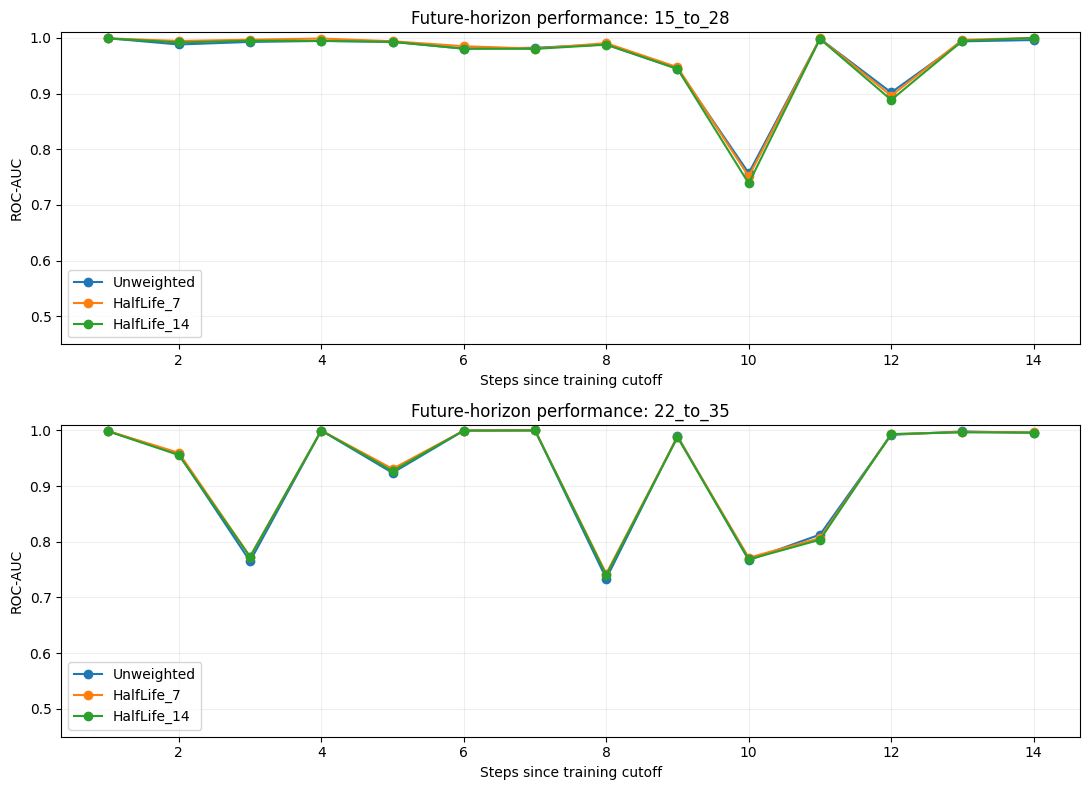


V11 complete!


In [20]:

import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score

# ======================================
# 1. DATA AND FEATURES
# ======================================

df = train_g.dropna(subset=["label"]).copy()
df["label"] = df["label"].astype(int)

features = base_cols + graph_cols

folds = {
    "15_to_28": (14, 15, 28),
    "22_to_35": (21, 22, 35)
}

# None = existing unweighted graph baseline
half_lives = [None, 4, 7, 14, 28]

results = []
horizon_results = []
fold_predictions = {}

# ======================================
# 2. FIXED MODEL CONFIGURATION
# ======================================

params = dict(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=31,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

for fold_name, (train_end, val_start, val_end) in folds.items():

    tr = df[df["time_step"] <= train_end].copy()
    va = df[
        df["time_step"].between(val_start, val_end)
    ].copy()

    fold_predictions[fold_name] = {}

    for half_life in half_lives:

        name = (
            "Unweighted" if half_life is None
            else f"HalfLife_{half_life}"
        )

        # Recency weights: most recent training
        # period has weight 1.
        if half_life is None:
            weights = np.ones(len(tr))
        else:
            age = train_end - tr["time_step"].to_numpy()
            weights = 2.0 ** (-age / half_life)

        # Normalise weights to mean 1
        weights = weights / weights.mean()

        model = lgb.LGBMClassifier(**params)

        model.fit(
            tr[features],
            tr["label"],
            sample_weight=weights
        )

        p = model.predict_proba(
            va[features]
        )[:, 1]

        fold_predictions[fold_name][name] = p

        auc = roc_auc_score(va["label"], p)
        ap = average_precision_score(va["label"], p)

        results.append({
            "fold": fold_name,
            "model": name,
            "roc_auc": auc,
            "pr_auc": ap
        })

        # Horizon = time elapsed since last
        # observed training period
        for step in sorted(va["time_step"].unique()):
            mask = va["time_step"] == step
            y = va.loc[mask, "label"]

            step_auc = (
                roc_auc_score(y, p[mask.to_numpy()])
                if y.nunique() == 2 else np.nan
            )

            horizon_results.append({
                "fold": fold_name,
                "model": name,
                "horizon": int(step - train_end),
                "time_step": int(step),
                "roc_auc": step_auc
            })

        print(
            f"{fold_name} | {name:13} "
            f"| AUC={auc:.5f} | AP={ap:.5f}"
        )

# ======================================
# 3. SUMMARY
# ======================================

results_df = pd.DataFrame(results)
horizon_df = pd.DataFrame(horizon_results)

auc_table = results_df.pivot(
    index="model",
    columns="fold",
    values="roc_auc"
)

auc_table["mean_auc"] = auc_table.mean(axis=1)
auc_table["worst_auc"] = auc_table[
    ["15_to_28", "22_to_35"]
].min(axis=1)

print("\n=== V11 ROC-AUC COMPARISON ===")
print(
    auc_table.sort_values(
        "mean_auc", ascending=False
    ).round(5).to_string()
)

print("\n=== V11 PR-AUC COMPARISON ===")
print(
    results_df.pivot(
        index="model",
        columns="fold",
        values="pr_auc"
    ).round(5).to_string()
)

# ======================================
# 4. HORIZON ANALYSIS
# ======================================

print("\n=== PER-HORIZON ROC-AUC ===")
print(
    horizon_df.pivot_table(
        index=["fold", "horizon"],
        columns="model",
        values="roc_auc"
    ).round(4).to_string()
)

# Compare baseline with weighting strategies
fig, axes = plt.subplots(2, 1, figsize=(11, 8))

for ax, fold_name in zip(axes, folds):
    subset = horizon_df[horizon_df["fold"] == fold_name]

    for name in ["Unweighted", "HalfLife_7", "HalfLife_14"]:
        s = subset[subset["model"] == name]
        ax.plot(
            s["horizon"],
            s["roc_auc"],
            marker="o",
            label=name
        )

    ax.set_title(f"Future-horizon performance: {fold_name}")
    ax.set_xlabel("Steps since training cutoff")
    ax.set_ylabel("ROC-AUC")
    ax.set_ylim(0.45, 1.01)
    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()

results_df.to_csv("v11_results.csv", index=False)
horizon_df.to_csv("v11_horizon_results.csv", index=False)

print("\nV11 complete!")


In [21]:

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

results = []

for fold_name, (train_end, val_start, val_end) in folds.items():

    tr = df[df["time_step"] <= train_end]
    va = df[df["time_step"].between(val_start, val_end)]

    preds = {}

    for half_life in [7, 28]:
        age = train_end - tr["time_step"].to_numpy()
        weights = 2.0 ** (-age / half_life)
        weights /= weights.mean()

        model = lgb.LGBMClassifier(
            n_estimators=300,
            learning_rate=0.03,
            num_leaves=31,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        )

        model.fit(
            tr[features],
            tr["label"],
            sample_weight=weights
        )

        preds[half_life] = model.predict_proba(
            va[features]
        )[:, 1]

    combinations = {
        "HalfLife_7": preds[7],
        "HalfLife_28": preds[28],
        "Blend_50_50": 0.5 * preds[7] + 0.5 * preds[28],
        "Blend_25_75": 0.25 * preds[7] + 0.75 * preds[28],
        "Blend_75_25": 0.75 * preds[7] + 0.25 * preds[28],
    }

    for name, pred in combinations.items():
        results.append({
            "fold": fold_name,
            "model": name,
            "roc_auc": roc_auc_score(va["label"], pred),
            "pr_auc": average_precision_score(va["label"], pred)
        })

results_df = pd.DataFrame(results)

print("\n=== V12 ROC-AUC ===")
print(
    results_df.pivot(
        index="model",
        columns="fold",
        values="roc_auc"
    ).round(5).to_string()
)

print("\n=== V12 PR-AUC ===")
print(
    results_df.pivot(
        index="model",
        columns="fold",
        values="pr_auc"
    ).round(5).to_string()
)



=== V12 ROC-AUC ===
fold         15_to_28  22_to_35
model                          
Blend_25_75   0.96534   0.91180
Blend_50_50   0.96655   0.90998
Blend_75_25   0.96744   0.90778
HalfLife_28   0.96367   0.91341
HalfLife_7    0.96826   0.90471

=== V12 PR-AUC ===
fold         15_to_28  22_to_35
model                          
Blend_25_75   0.91125   0.81705
Blend_50_50   0.91529   0.81609
Blend_75_25   0.91773   0.81483
HalfLife_28   0.90559   0.81774
HalfLife_7    0.91938   0.81300


In [22]:

import numpy as np
import pandas as pd
import lightgbm as lgb

# All known labels from time steps 1–35
final_train = train_g.dropna(subset=["label"]).copy()
final_train["label"] = final_train["label"].astype(int)

features = base_cols + graph_cols

# Weight recent transactions more heavily
age = 35 - final_train["time_step"].to_numpy()
weights = 2.0 ** (-age / 28)
weights = weights / weights.mean()

# Fit final weighted graph model
model_v3 = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=31,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

model_v3.fit(
    final_train[features],
    final_train["label"],
    sample_weight=weights
)

pred_v3 = model_v3.predict_proba(
    test_g[features]
)[:, 1]

# Generate exactly one submission CSV
submission_v3 = pd.DataFrame({
    "index": test_g["index"].to_numpy(),
    "target": pred_v3
})

assert len(submission_v3) == len(test)
assert submission_v3["index"].equals(test["index"])
assert np.isfinite(pred_v3).all()
assert submission_v3["target"].between(0, 1).all()

submission_v3.to_csv(
    "submission_weighted_graph_hl28.csv",
    index=False
)

print(submission_v3.head())
print("Saved submission_weighted_graph_hl28.csv")


   index    target
0      0  0.000388
1      1  0.000862
2      2  0.000592
3      3  0.000609
4      4  0.000151
Saved submission_weighted_graph_hl28.csv


In [23]:

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

# ============================================
# V13: MULTI-HOP BITCOIN GRAPH FEATURES
# ============================================

base_cols = [f"feat_{i}" for i in range(1, 166)]

# Important original features, based on V7/V9
agg_cols = [
    "feat_2", "feat_53", "feat_58",
    "feat_16", "feat_90", "feat_138",
    "feat_142", "feat_163",
    "feat_52", "feat_8", "feat_100",
    "feat_47"
]

# Smaller subset for 2-hop aggregation
hop2_cols = [
    "feat_2", "feat_53", "feat_58",
    "feat_16", "feat_90", "feat_138",
    "feat_142", "feat_163"
]

nodes = pd.concat(
    [
        train[["txId", "time_step"] + agg_cols],
        test[["txId", "time_step"] + agg_cols]
    ],
    ignore_index=True
)

assert nodes["txId"].is_unique

e = edges[["txId1", "txId2"]].copy()

# --------------------------------------------
# 1. NODE DEGREE
# --------------------------------------------

in_degree = e.groupby("txId2").size()
out_degree = e.groupby("txId1").size()

nodes["g_in_degree"] = (
    nodes["txId"].map(in_degree).fillna(0)
)
nodes["g_out_degree"] = (
    nodes["txId"].map(out_degree).fillna(0)
)
nodes["g_total_degree"] = (
    nodes["g_in_degree"] + nodes["g_out_degree"]
)
nodes["g_degree_ratio"] = (
    (nodes["g_in_degree"] + 1) /
    (nodes["g_out_degree"] + 1)
)

# --------------------------------------------
# 2. GENERIC NEIGHBOR AGGREGATION
# --------------------------------------------

def neighbor_aggregate(
    edges_df, source_table, source_id,
    target_id, selected_cols, prefix,
    statistics=("mean", "std", "max")
):
    lookup = source_table[
        ["txId"] + selected_cols
    ].rename(columns={"txId": source_id})

    joined = edges_df[[source_id, target_id]].merge(
        lookup,
        on=source_id,
        how="left",
        validate="many_to_one"
    )

    grouped = joined.groupby(target_id)

    output = grouped[selected_cols].agg(
        list(statistics)
    )
    output.columns = [
        f"{prefix}_{col}_{stat}"
        for col, stat in output.columns
    ]

    output[f"{prefix}_neighbors"] = grouped.size()
    output[f"{prefix}_known_neighbors"] = (
        grouped[selected_cols[0]].count()
    )

    return output.reset_index().rename(
        columns={target_id: "txId"}
    )

# --------------------------------------------
# 3. ONE-HOP UPSTREAM FEATURES
# --------------------------------------------

source_degree = nodes[
    [
        "txId",
        "g_in_degree",
        "g_out_degree",
        "g_total_degree"
    ] + agg_cols
]

up1 = neighbor_aggregate(
    e, source_degree,
    "txId1", "txId2",
    agg_cols + [
        "g_in_degree",
        "g_out_degree",
        "g_total_degree"
    ],
    "g_up1"
)

# --------------------------------------------
# 4. TWO-HOP UPSTREAM FEATURES
# --------------------------------------------

# First-hop means at each intermediate node
hop2_input = [
    f"g_up1_{c}_mean" for c in hop2_cols
]

# Also aggregate predecessor connectivity
hop2_input += [
    "g_up1_g_in_degree_mean",
    "g_up1_g_out_degree_mean"
]

# Rename creates the same lookup structure
up2 = neighbor_aggregate(
    e, up1[["txId"] + hop2_input],
    "txId1", "txId2",
    hop2_input,
    "g_up2",
    statistics=("mean", "max")
)

# Two-hop features are aggregated summaries
# over first-hop neighbours' own incoming
# neighbourhoods. They are not necessarily
# statistics over unique two-hop nodes.

# --------------------------------------------
# 5. DOWNSTREAM FEATURES (EXPERIMENTAL)
# --------------------------------------------

# Downstream information may not exist when
# a transaction is first classified.
# Keep this as a separate ablation.

down1 = neighbor_aggregate(
    e, source_degree,
    "txId2", "txId1",
    agg_cols + [
        "g_in_degree",
        "g_out_degree",
        "g_total_degree"
    ],
    "g_down1"
)

# --------------------------------------------
# 6. COMBINE FEATURES
# --------------------------------------------

degree_cols = [
    "txId", "g_in_degree", "g_out_degree",
    "g_total_degree", "g_degree_ratio"
]

full_graph = nodes[degree_cols].copy()

for part in [up1, up2, down1]:
    full_graph = full_graph.merge(
        part,
        on="txId",
        how="left",
        validate="one_to_one"
    )

train_v13 = train.merge(
    full_graph,
    on="txId",
    how="left",
    sort=False,
    validate="one_to_one"
)
test_v13 = test.merge(
    full_graph,
    on="txId",
    how="left",
    sort=False,
    validate="one_to_one"
)

assert len(train_v13) == len(train)
assert len(test_v13) == len(test)
assert test_v13["index"].equals(test["index"])

# LightGBM can handle NaN in aggregates,
# which indicate unavailable neighbour data.

upstream_cols = [
    c for c in full_graph.columns
    if c.startswith(("g_in_", "g_out_",
                     "g_total_", "g_degree_",
                     "g_up1_", "g_up2_"))
]

downstream_cols = [
    c for c in full_graph.columns
    if c.startswith("g_down1_")
]

print("Upstream graph features:", len(upstream_cols))
print("Downstream graph features:", len(downstream_cols))

# --------------------------------------------
# 7. COMPARE FEATURE GROUPS
# --------------------------------------------

labelled_v13 = train_v13.dropna(
    subset=["label"]
).copy()
labelled_v13["label"] = (
    labelled_v13["label"].astype(int)
)

feature_sets = {
    "Original": base_cols,
    "Upstream_multi_hop": base_cols + upstream_cols,
    "Upstream_no_feat2": [
        c for c in base_cols if c != "feat_2"
    ] + upstream_cols,
    "Full_graph_experimental": (
        base_cols + upstream_cols + downstream_cols
    ),
}

folds = {
    "15_to_28": (14, 15, 28),
    "22_to_35": (21, 22, 35),
    "29_to_35": (28, 29, 35)
}

results = []

for fold, (train_end, start, end) in folds.items():
    tr = labelled_v13[
        labelled_v13["time_step"] <= train_end
    ]
    va = labelled_v13[
        labelled_v13["time_step"].between(start, end)
    ]

    for name, cols in feature_sets.items():

        model = lgb.LGBMClassifier(
            n_estimators=300,
            learning_rate=0.03,
            num_leaves=31,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        )

        model.fit(tr[cols], tr["label"])

        p = model.predict_proba(va[cols])[:, 1]

        results.append({
            "fold": fold,
            "model": name,
            "roc_auc": roc_auc_score(
                va["label"], p
            ),
            "pr_auc": average_precision_score(
                va["label"], p
            )
        })

        print(
            f"{fold:10} | {name:25} "
            f"| AUC={results[-1]['roc_auc']:.5f}"
        )

results_v13 = pd.DataFrame(results)

print("\n=== V13 ROC-AUC ===")
print(
    results_v13.pivot(
        index="model",
        columns="fold",
        values="roc_auc"
    ).round(5).to_string()
)

print("\n=== V13 PR-AUC ===")
print(
    results_v13.pivot(
        index="model",
        columns="fold",
        values="pr_auc"
    ).round(5).to_string()
)

results_v13.to_csv("v13_results.csv", index=False)
print("\nV13 complete!")


Upstream graph features: 73
Downstream graph features: 47
15_to_28   | Original                  | AUC=0.96564
15_to_28   | Upstream_multi_hop        | AUC=0.95884
15_to_28   | Upstream_no_feat2         | AUC=0.96941
15_to_28   | Full_graph_experimental   | AUC=0.96395
22_to_35   | Original                  | AUC=0.89285
22_to_35   | Upstream_multi_hop        | AUC=0.90172
22_to_35   | Upstream_no_feat2         | AUC=0.88182
22_to_35   | Full_graph_experimental   | AUC=0.90330
29_to_35   | Original                  | AUC=0.99629
29_to_35   | Upstream_multi_hop        | AUC=0.99626
29_to_35   | Upstream_no_feat2         | AUC=0.99740
29_to_35   | Full_graph_experimental   | AUC=0.99643

=== V13 ROC-AUC ===
fold                     15_to_28  22_to_35  29_to_35
model                                                
Full_graph_experimental   0.96395   0.90330   0.99643
Original                  0.96564   0.89285   0.99629
Upstream_multi_hop        0.95884   0.90172   0.99626
Upstream_no_fea

In [24]:

import pandas as pd
import numpy as np

# ============================================
# V14A: CHECK WHETHER LABEL PROPAGATION IS VIABLE
# ============================================

# All transaction IDs and time steps
nodes = pd.concat([
    train[["txId", "time_step"]],
    test[["txId", "time_step"]]
]).drop_duplicates("txId")

# Add time information to both endpoints
edge_check = edges.merge(
    nodes.rename(columns={
        "txId": "txId1",
        "time_step": "source_step"
    }),
    on="txId1", how="left"
).merge(
    nodes.rename(columns={
        "txId": "txId2",
        "time_step": "dest_step"
    }),
    on="txId2", how="left"
)

known_edges = edge_check.dropna(
    subset=["source_step", "dest_step"]
)

same_step = (
    known_edges["source_step"]
    == known_edges["dest_step"]
)

print("=== GRAPH TEMPORAL STRUCTURE ===")
print("Total edges:", len(edges))
print("Edges with both endpoint time steps known:",
      len(known_edges))
print("Same-step edges:", same_step.sum())
print("Cross-step edges:", (~same_step).sum())
print("Same-step proportion:",
      round(same_step.mean(), 5))

# ============================================
# LABEL AVAILABILITY FOR TEST NEIGHBOURS
# ============================================

known_labels = train.loc[
    train["label"].notna(), ["txId", "label"]
].copy()

label_ids = set(known_labels["txId"])
test_ids = set(test["txId"])

# Incoming test edges with a known labelled source
test_incoming = edges[
    edges["txId2"].isin(test_ids)
].copy()

test_incoming["source_has_label"] = (
    test_incoming["txId1"].isin(label_ids)
)

# Outgoing test edges with a known labelled destination
test_outgoing = edges[
    edges["txId1"].isin(test_ids)
].copy()

test_outgoing["dest_has_label"] = (
    test_outgoing["txId2"].isin(label_ids)
)

print("\n=== TEST LABEL PROPAGATION FEASIBILITY ===")

print("Incoming edges to test nodes:",
      len(test_incoming))

print("Incoming edges from labelled train nodes:",
      test_incoming["source_has_label"].sum())

print("Outgoing edges from test nodes:",
      len(test_outgoing))

print("Outgoing edges to labelled train nodes:",
      test_outgoing["dest_has_label"].sum())

# Number of test transactions with a known
# labelled neighbour in the supplied graph
reachable_test = (
    set(test_incoming.loc[
        test_incoming["source_has_label"], "txId2"
    ])
    |
    set(test_outgoing.loc[
        test_outgoing["dest_has_label"], "txId1"
    ])
)

print("\nTest transactions:", len(test))
print("Test transactions with labelled train neighbour:",
      len(reachable_test))
print("Percentage with labelled train neighbour:",
      round(100 * len(reachable_test) / len(test), 4))

if len(reachable_test) == 0:
    print("\nCONCLUSION:")
    print("Direct training-label propagation cannot reach")
    print("the test transactions through supplied edges.")
    print("Do not build label-neighbour features as")
    print("the primary submission strategy.")
else:
    print("\nCONCLUSION:")
    print("Some test transactions connect to known labels.")
    print("Label propagation may be worth testing,")
    print("subject to leakage-safe temporal validation.")


=== GRAPH TEMPORAL STRUCTURE ===
Total edges: 234355
Edges with both endpoint time steps known: 175918
Same-step edges: 175918
Cross-step edges: 0
Same-step proportion: 1.0

=== TEST LABEL PROPAGATION FEASIBILITY ===
Incoming edges to test nodes: 30930
Incoming edges from labelled train nodes: 0
Outgoing edges from test nodes: 18763
Outgoing edges to labelled train nodes: 0

Test transactions: 15329
Test transactions with labelled train neighbour: 0
Percentage with labelled train neighbour: 0.0

CONCLUSION:
Direct training-label propagation cannot reach
the test transactions through supplied edges.
Do not build label-neighbour features as
the primary submission strategy.


In [26]:

import numpy as np
import pandas as pd
import lightgbm as lgb

from scipy.sparse import csr_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, average_precision_score

# ==================================================
# V15: COMPACT MULTI-HOP GRAPH REPRESENTATIONS
# ==================================================

base_cols = [f"feat_{i}" for i in range(1, 166)]
N_COMPONENTS = 16

# All nodes whose transaction features are available
nodes15 = pd.concat(
    [
        train[["txId", "time_step"] + base_cols],
        test[["txId", "time_step"] + base_cols]
    ],
    ignore_index=True
)

assert nodes15["txId"].is_unique

n = len(nodes15)

# Map graph endpoints to node positions.
# Edges with unavailable endpoint features are
# excluded from feature aggregation.
id_to_pos = pd.Series(
    np.arange(n),
    index=nodes15["txId"]
)

src = edges["txId1"].map(id_to_pos)
dst = edges["txId2"].map(id_to_pos)

valid = src.notna() & dst.notna()

src = src[valid].to_numpy(dtype=np.int32)
dst = dst[valid].to_numpy(dtype=np.int32)

# A_in[i, j] = 1 when j -> i.
# A_out[i, j] = 1 when i -> j.
A_in_raw = csr_matrix(
    (
        np.ones(len(src), dtype=np.float32),
        (dst, src)
    ),
    shape=(n, n)
)

A_out_raw = A_in_raw.T.tocsr()

def normalise_rows(A):
    degrees = np.asarray(A.sum(axis=1)).ravel()
    inv = np.divide(
        1.0,
        degrees,
        out=np.zeros_like(degrees),
        where=degrees > 0
    )
    return A.multiply(inv[:, None]).tocsr(), degrees

A_in, known_in_degree = normalise_rows(A_in_raw)
A_out, known_out_degree = normalise_rows(A_out_raw)

print("Nodes with features:", n)
print("Edges used:", len(src))
print("Known incoming links:", int(known_in_degree.sum()))

# ==================================================
# BUILD EMBEDDINGS FOR ONE TRAINING CUTOFF
# ==================================================

X_all = nodes15[base_cols].to_numpy(
    dtype=np.float32
)

def make_embeddings(train_end):

    # Fit scaler and PCA only on historical
    # transaction features <= training cutoff.
    fit_mask = (
        nodes15["time_step"].to_numpy() <= train_end
    )

    scaler = StandardScaler()
    X_fit = scaler.fit_transform(X_all[fit_mask])

    pca = PCA(
        n_components=N_COMPONENTS,
        svd_solver="randomized",
        random_state=42
    )
    pca.fit(X_fit)

    # Transform released node features.
    # This uses NO validation/test labels.
    X_scaled = scaler.transform(X_all)
    Z = pca.transform(X_scaled).astype(np.float32)

    # First-hop incoming and outgoing means
    up1 = A_in @ Z
    down1 = A_out @ Z

    # Two-hop aggregates of first-hop means
    up2 = A_in @ up1
    down2 = A_out @ down1

    components = {
        "pc_self": Z,
        "pc_up1": up1,
        "pc_up2": up2,
        "pc_down1": down1,
        "pc_down2": down2,
    }

    features = pd.DataFrame({
        "txId": nodes15["txId"].to_numpy(),
        "pc_known_in_degree": known_in_degree,
        "pc_known_out_degree": known_out_degree,
    })

    for prefix, matrix in components.items():
        cols = [
            f"{prefix}_{j}"
            for j in range(N_COMPONENTS)
        ]
        block = pd.DataFrame(matrix, columns=cols)
        features = pd.concat(
            [features, block],
            axis=1
        )

    return features, pca.explained_variance_ratio_.sum()


# ==================================================
# EVALUATION
# ==================================================

labelled15 = train.dropna(
    subset=["label"]
).copy()

labelled15["label"] = (
    labelled15["label"].astype(int)
)

v15_folds = {
    "15_to_28": (14, 15, 28),
    "22_to_35": (21, 22, 35),
    "29_to_35": (28, 29, 35)
}

v15_results = []

for fold_name, (train_end, start, end) in v15_folds.items():
    print(f"\nBuilding PCA graph features for {fold_name}...")

    embeddings, variance = make_embeddings(train_end)

    # Join generated features onto labelled rows,
    # keeping their original order.
    data = labelled15.merge(
        embeddings,
        on="txId",
        how="left",
        validate="one_to_one",
        sort=False
    )

    # Retain V7 one-hop graph features as well
    v7_extra = train_g[
        ["txId"] + graph_cols
    ]

    data = data.merge(
        v7_extra,
        on="txId",
        how="left",
        validate="one_to_one",
        sort=False
    )

    tr = data[data["time_step"] <= train_end]
    va = data[data["time_step"].between(start, end)]

    pc_self = [
        f"pc_self_{j}" for j in range(N_COMPONENTS)
    ]

    pc_up = [
        f"pc_up{hop}_{j}"
        for hop in [1, 2]
        for j in range(N_COMPONENTS)
    ]

    pc_down = [
        f"pc_down{hop}_{j}"
        for hop in [1, 2]
        for j in range(N_COMPONENTS)
    ]

    degree_cols = [
        "pc_known_in_degree",
        "pc_known_out_degree"
    ]

    feature_sets = {
        "Original": base_cols,

        "V7_upstream": (
            base_cols + graph_cols
        ),

        "PCA_upstream": (
            base_cols + pc_self
            + pc_up + degree_cols
        ),

        "PCA_upstream_plus_V7": (
            base_cols + graph_cols
            + pc_self + pc_up + degree_cols
        ),

        "PCA_bidirectional": (
            base_cols + pc_self
            + pc_up + pc_down + degree_cols
        )
    }

    print(
        f"PCA variance explained: {variance:.2%}"
    )

    for name, cols in feature_sets.items():

        model = lgb.LGBMClassifier(
            n_estimators=300,
            learning_rate=0.03,
            num_leaves=31,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        )

        model.fit(
            tr[cols],
            tr["label"]
        )

        pred = model.predict_proba(
            va[cols]
        )[:, 1]

        auc = roc_auc_score(
            va["label"], pred
        )

        ap = average_precision_score(
            va["label"], pred
        )

        v15_results.append({
            "fold": fold_name,
            "model": name,
            "roc_auc": auc,
            "pr_auc": ap
        })

        print(
            f"{name:26} "
            f"AUC={auc:.5f} AP={ap:.5f}"
        )

# ==================================================
# RESULTS
# ==================================================

v15_results_df = pd.DataFrame(v15_results)

print("\n=== V15 ROC-AUC ===")
print(
    v15_results_df.pivot(
        index="model",
        columns="fold",
        values="roc_auc"
    ).round(5).to_string()
)

print("\n=== V15 PR-AUC ===")
print(
    v15_results_df.pivot(
        index="model",
        columns="fold",
        values="pr_auc"
    ).round(5).to_string()
)

v15_results_df.to_csv(
    "v15_results.csv",
    index=False
)

print("\nV15 complete!")


Nodes with features: 157101
Edges used: 175918
Known incoming links: 175918

Building PCA graph features for 15_to_28...
PCA variance explained: 56.65%
Original                   AUC=0.96564 AP=0.89806
V7_upstream                AUC=0.96598 AP=0.90689
PCA_upstream               AUC=0.96002 AP=0.89055
PCA_upstream_plus_V7       AUC=0.96234 AP=0.89050
PCA_bidirectional          AUC=0.96601 AP=0.90742

Building PCA graph features for 22_to_35...
PCA variance explained: 56.57%
Original                   AUC=0.89285 AP=0.80540
V7_upstream                AUC=0.90163 AP=0.81081
PCA_upstream               AUC=0.88691 AP=0.80182
PCA_upstream_plus_V7       AUC=0.88391 AP=0.80131
PCA_bidirectional          AUC=0.87804 AP=0.79848

Building PCA graph features for 29_to_35...
PCA variance explained: 56.97%
Original                   AUC=0.99629 AP=0.98658
V7_upstream                AUC=0.99620 AP=0.98651
PCA_upstream               AUC=0.99676 AP=0.98809
PCA_upstream_plus_V7       AUC=0.99680 AP=0.98

In [27]:

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

df = train_g.dropna(subset=["label"]).copy()
df["label"] = df["label"].astype(int)

features = base_cols + graph_cols

folds = {
    "15_to_28": (14, 15, 28),
    "22_to_35": (21, 22, 35)
}

results = []

for fold_name, (train_end, val_start, val_end) in folds.items():

    tr = df[df["time_step"] <= train_end].copy()
    va = df[
        df["time_step"].between(val_start, val_end)
    ].copy()

    # Size of each labelled time-step group
    counts = tr.groupby("time_step")["label"].transform("size")
    counts = counts.to_numpy()

    # More recent data receives more weight
    age = train_end - tr["time_step"].to_numpy()
    recency = 2.0 ** (-age / 28)

    weighting = {
        "Unweighted": np.ones(len(tr)),
        "Step_balanced": 1.0 / counts,
        "Step_sqrt_balanced": 1.0 / np.sqrt(counts),
        "Step_balanced_recent": (1.0 / counts) * recency,
        "Step_sqrt_recent": (1.0 / np.sqrt(counts)) * recency
    }

    for name, weights in weighting.items():
        weights = weights / weights.mean()

        model = lgb.LGBMClassifier(
            n_estimators=300,
            learning_rate=0.03,
            num_leaves=31,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        )

        model.fit(
            tr[features],
            tr["label"],
            sample_weight=weights
        )

        pred = model.predict_proba(
            va[features]
        )[:, 1]

        results.append({
            "fold": fold_name,
            "model": name,
            "roc_auc": roc_auc_score(va["label"], pred),
            "pr_auc": average_precision_score(va["label"], pred)
        })

results_v16 = pd.DataFrame(results)

print("\n=== V16 ROC-AUC ===")
print(
    results_v16.pivot(
        index="model",
        columns="fold",
        values="roc_auc"
    ).round(5).to_string()
)

print("\n=== V16 PR-AUC ===")
print(
    results_v16.pivot(
        index="model",
        columns="fold",
        values="pr_auc"
    ).round(5).to_string()
)



=== V16 ROC-AUC ===
fold                  15_to_28  22_to_35
model                                   
Step_balanced          0.97208   0.90207
Step_balanced_recent   0.96545   0.91065
Step_sqrt_balanced     0.96564   0.90619
Step_sqrt_recent       0.96708   0.90774
Unweighted             0.96598   0.90163

=== V16 PR-AUC ===
fold                  15_to_28  22_to_35
model                                   
Step_balanced          0.92088   0.81238
Step_balanced_recent   0.91726   0.81652
Step_sqrt_balanced     0.91350   0.81366
Step_sqrt_recent       0.91373   0.81470
Unweighted             0.90689   0.81081


In [28]:

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

df = train_g.dropna(subset=["label"]).copy()
df["label"] = df["label"].astype(int)

features = base_cols + graph_cols

folds = {
    "15_to_28": (14, 15, 28),
    "22_to_35": (21, 22, 35)
}

results = []

params = dict(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=31,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

for fold_name, (train_end, val_start, val_end) in folds.items():

    tr = df[df["time_step"] <= train_end].copy()
    va = df[df["time_step"].between(val_start, val_end)].copy()

    counts = (
        tr.groupby("time_step")["label"]
        .transform("size")
        .to_numpy()
    )

    age = train_end - tr["time_step"].to_numpy()

    weight_sets = {
        "Step_balanced": 1.0 / counts,
        "HalfLife_28": 2.0 ** (-age / 28)
    }

    preds = {}

    for name, weights in weight_sets.items():
        weights = weights / weights.mean()

        model = lgb.LGBMClassifier(**params)
        model.fit(
            tr[features],
            tr["label"],
            sample_weight=weights
        )

        preds[name] = model.predict_proba(
            va[features]
        )[:, 1]

    combinations = {
        "Step_balanced": preds["Step_balanced"],
        "HalfLife_28": preds["HalfLife_28"],
        "Blend_50_50": (
            0.50 * preds["Step_balanced"]
            + 0.50 * preds["HalfLife_28"]
        ),
        "Blend_25_75": (
            0.25 * preds["Step_balanced"]
            + 0.75 * preds["HalfLife_28"]
        ),
        "Blend_75_25": (
            0.75 * preds["Step_balanced"]
            + 0.25 * preds["HalfLife_28"]
        )
    }

    for name, pred in combinations.items():
        results.append({
            "fold": fold_name,
            "model": name,
            "roc_auc": roc_auc_score(va["label"], pred),
            "pr_auc": average_precision_score(va["label"], pred)
        })

results_v17 = pd.DataFrame(results)

print("\n=== V17 ROC-AUC ===")
print(
    results_v17.pivot(
        index="model",
        columns="fold",
        values="roc_auc"
    ).round(5).to_string()
)

print("\n=== V17 PR-AUC ===")
print(
    results_v17.pivot(
        index="model",
        columns="fold",
        values="pr_auc"
    ).round(5).to_string()
)



=== V17 ROC-AUC ===
fold           15_to_28  22_to_35
model                            
Blend_25_75     0.96690   0.91108
Blend_50_50     0.96910   0.90869
Blend_75_25     0.97076   0.90593
HalfLife_28     0.96367   0.91341
Step_balanced   0.97208   0.90207

=== V17 PR-AUC ===
fold           15_to_28  22_to_35
model                            
Blend_25_75     0.91152   0.81686
Blend_50_50     0.91596   0.81573
Blend_75_25     0.91876   0.81437
HalfLife_28     0.90559   0.81774
Step_balanced   0.92088   0.81238


In [29]:

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

# =====================================================
# V18: TIME-STEP RELATIVE FEATURE ENGINEERING
# =====================================================

# IMPORTANT:
# Use only original features for these transformations.
# Select features by name, not using validation labels.

relative_cols = [
    "feat_2", "feat_53", "feat_58",
    "feat_16", "feat_90", "feat_138",
    "feat_142", "feat_163",
    "feat_52", "feat_8", "feat_100",
    "feat_47", "feat_1", "feat_3",
    "feat_4", "feat_5", "feat_6",
    "feat_7", "feat_9", "feat_10",
    "feat_11", "feat_12", "feat_13",
    "feat_14", "feat_15"
]

# Use all available transaction feature vectors,
# including unknown-label rows, when calculating
# statistics within the SAME time step.
#
# No label information is used.

all_nodes = pd.concat(
    [
        train[["txId", "time_step"] + relative_cols],
        test[["txId", "time_step"] + relative_cols]
    ],
    ignore_index=True
)

assert all_nodes["txId"].is_unique

# =====================================================
# 1. GENERATE PERCENTILE RANK FEATURES
# =====================================================

rank_features = all_nodes.groupby("time_step")[
    relative_cols
].rank(pct=True)

rank_features.columns = [
    f"rank_{c}" for c in relative_cols
]

# =====================================================
# 2. GENERATE WITHIN-STEP Z-SCORES
# =====================================================

step_mean = all_nodes.groupby("time_step")[
    relative_cols
].transform("mean")

step_std = all_nodes.groupby("time_step")[
    relative_cols
].transform("std")

z_features = (
    all_nodes[relative_cols] - step_mean
) / step_std.replace(0, np.nan)

z_features = z_features.replace(
    [np.inf, -np.inf], np.nan
).fillna(0)

z_features.columns = [
    f"z_{c}" for c in relative_cols
]

relative_features = pd.concat(
    [
        all_nodes[["txId"]].reset_index(drop=True),
        rank_features.reset_index(drop=True),
        z_features.reset_index(drop=True)
    ],
    axis=1
)

assert relative_features["txId"].is_unique

# =====================================================
# 3. MERGE WITH EXISTING V7 GRAPH FEATURES
# =====================================================

train_v18 = train_g.merge(
    relative_features,
    on="txId",
    how="left",
    validate="one_to_one",
    sort=False
)

test_v18 = test_g.merge(
    relative_features,
    on="txId",
    how="left",
    validate="one_to_one",
    sort=False
)

assert len(train_v18) == len(train)
assert len(test_v18) == len(test)
assert test_v18["index"].equals(test["index"])

rank_cols = [
    f"rank_{c}" for c in relative_cols
]

z_cols = [
    f"z_{c}" for c in relative_cols
]

print("Rank features:", len(rank_cols))
print("Z-score features:", len(z_cols))
print("Total new features:", len(rank_cols) + len(z_cols))

# =====================================================
# 4. CHRONOLOGICAL VALIDATION
# =====================================================

labelled_v18 = train_v18.dropna(
    subset=["label"]
).copy()

labelled_v18["label"] = (
    labelled_v18["label"].astype(int)
)

feature_sets = {
    "V7_baseline": base_cols + graph_cols,

    "V18_ranks": (
        base_cols + graph_cols + rank_cols
    ),

    "V18_zscores": (
        base_cols + graph_cols + z_cols
    ),

    "V18_ranks_zscores": (
        base_cols + graph_cols
        + rank_cols + z_cols
    )
}

folds_v18 = {
    "15_to_28": (14, 15, 28),
    "22_to_35": (21, 22, 35),
    "29_to_35": (28, 29, 35)
}

results_v18 = []

for fold_name, (train_end, start, end) in folds_v18.items():

    tr = labelled_v18[
        labelled_v18["time_step"] <= train_end
    ]

    va = labelled_v18[
        labelled_v18["time_step"].between(start, end)
    ]

    for name, cols in feature_sets.items():

        model = lgb.LGBMClassifier(
            n_estimators=300,
            learning_rate=0.03,
            num_leaves=31,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        )

        model.fit(
            tr[cols],
            tr["label"]
        )

        pred = model.predict_proba(
            va[cols]
        )[:, 1]

        auc = roc_auc_score(
            va["label"], pred
        )

        ap = average_precision_score(
            va["label"], pred
        )

        results_v18.append({
            "fold": fold_name,
            "model": name,
            "roc_auc": auc,
            "pr_auc": ap
        })

        print(
            f"{fold_name:10} | {name:20} "
            f"| AUC={auc:.5f} | AP={ap:.5f}"
        )

results_v18_df = pd.DataFrame(results_v18)

print("\n=== V18 ROC-AUC ===")
print(
    results_v18_df.pivot(
        index="model",
        columns="fold",
        values="roc_auc"
    ).round(5).to_string()
)

print("\n=== V18 PR-AUC ===")
print(
    results_v18_df.pivot(
        index="model",
        columns="fold",
        values="pr_auc"
    ).round(5).to_string()
)

results_v18_df.to_csv(
    "v18_results.csv",
    index=False
)

print("\nV18 complete!")


Rank features: 25
Z-score features: 25
Total new features: 50
15_to_28   | V7_baseline          | AUC=0.96598 | AP=0.90689
15_to_28   | V18_ranks            | AUC=0.95636 | AP=0.87768
15_to_28   | V18_zscores          | AUC=0.95271 | AP=0.85670
15_to_28   | V18_ranks_zscores    | AUC=0.95365 | AP=0.86491
22_to_35   | V7_baseline          | AUC=0.90163 | AP=0.81081
22_to_35   | V18_ranks            | AUC=0.90331 | AP=0.80884
22_to_35   | V18_zscores          | AUC=0.89684 | AP=0.80819
22_to_35   | V18_ranks_zscores    | AUC=0.89459 | AP=0.80474
29_to_35   | V7_baseline          | AUC=0.99620 | AP=0.98651
29_to_35   | V18_ranks            | AUC=0.99628 | AP=0.98592
29_to_35   | V18_zscores          | AUC=0.99698 | AP=0.98864
29_to_35   | V18_ranks_zscores    | AUC=0.99660 | AP=0.98704

=== V18 ROC-AUC ===
fold               15_to_28  22_to_35  29_to_35
model                                          
V18_ranks           0.95636   0.90331   0.99628
V18_ranks_zscores   0.95365   0.89459   0

In [30]:

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

df = train.dropna(subset=["label"]).copy()
df["label"] = df["label"].astype(int)

all_cols = [f"feat_{i}" for i in range(1, 166)]
group_a = all_cols[:94]
group_b = all_cols[94:]

folds = {
    "15_to_28": (14, 15, 28),
    "22_to_35": (21, 22, 35)
}

params = dict(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=31,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

results = []

for fold_name, (train_end, start, end) in folds.items():

    tr = df[df["time_step"] <= train_end]
    va = df[df["time_step"].between(start, end)]

    predictions = {}

    for name, cols in {
        "All_165": all_cols,
        "First_94": group_a,
        "Last_71": group_b
    }.items():

        model = lgb.LGBMClassifier(**params)
        model.fit(tr[cols], tr["label"])

        predictions[name] = (
            model.predict_proba(va[cols])[:, 1]
        )

    predictions["Group_blend_50_50"] = (
        0.5 * predictions["First_94"]
        + 0.5 * predictions["Last_71"]
    )

    predictions["All_plus_groups"] = (
        0.5 * predictions["All_165"]
        + 0.25 * predictions["First_94"]
        + 0.25 * predictions["Last_71"]
    )

    for name, pred in predictions.items():
        results.append({
            "fold": fold_name,
            "model": name,
            "roc_auc": roc_auc_score(
                va["label"], pred
            ),
            "pr_auc": average_precision_score(
                va["label"], pred
            )
        })

results_v19 = pd.DataFrame(results)

print("\n=== V19 ROC-AUC ===")
print(
    results_v19.pivot(
        index="model",
        columns="fold",
        values="roc_auc"
    ).round(5).to_string()
)

print("\n=== V19 PR-AUC ===")
print(
    results_v19.pivot(
        index="model",
        columns="fold",
        values="pr_auc"
    ).round(5).to_string()
)



=== V19 ROC-AUC ===
fold               15_to_28  22_to_35
model                                
All_165             0.96564   0.89285
All_plus_groups     0.97328   0.91198
First_94            0.96413   0.86955
Group_blend_50_50   0.96955   0.91507
Last_71             0.95924   0.91190

=== V19 PR-AUC ===
fold               15_to_28  22_to_35
model                                
All_165             0.89806   0.80540
All_plus_groups     0.91676   0.81828
First_94            0.90352   0.78948
Group_blend_50_50   0.90383   0.81670
Last_71             0.87691   0.78474


In [31]:

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

df = train_g.dropna(subset=["label"]).copy()
df["label"] = df["label"].astype(int)

all_cols = [f"feat_{i}" for i in range(1, 166)]
first_94 = all_cols[:94]
last_71 = all_cols[94:]
graph_features = all_cols + graph_cols

folds = {
    "15_to_28": (14, 15, 28),
    "22_to_35": (21, 22, 35)
}

params = dict(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=31,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

results = []

for fold_name, (train_end, start, end) in folds.items():

    tr = df[df["time_step"] <= train_end]
    va = df[df["time_step"].between(start, end)]

    preds = {}

    # Original + two feature-group specialists
    for name, cols in {
        "All": all_cols,
        "First94": first_94,
        "Last71": last_71
    }.items():
        model = lgb.LGBMClassifier(**params)
        model.fit(tr[cols], tr["label"])
        preds[name] = model.predict_proba(va[cols])[:, 1]

    # Weighted V7 graph model
    age = train_end - tr["time_step"].to_numpy()
    weights = 2.0 ** (-age / 28)
    weights /= weights.mean()

    graph_model = lgb.LGBMClassifier(**params)
    graph_model.fit(
        tr[graph_features],
        tr["label"],
        sample_weight=weights
    )

    preds["WeightedGraph"] = graph_model.predict_proba(
        va[graph_features]
    )[:, 1]

    group_blend = (
        0.5 * preds["First94"]
        + 0.5 * preds["Last71"]
    )

    all_plus_groups = (
        0.5 * preds["All"]
        + 0.25 * preds["First94"]
        + 0.25 * preds["Last71"]
    )

    combinations = {
        "Group_blend": group_blend,
        "All_plus_groups": all_plus_groups,
        "Weighted_graph": preds["WeightedGraph"],
        "Group_plus_graph": (
            0.5 * group_blend
            + 0.5 * preds["WeightedGraph"]
        ),
        "All_groups_plus_graph": (
            0.5 * all_plus_groups
            + 0.5 * preds["WeightedGraph"]
        )
    }

    for name, pred in combinations.items():
        results.append({
            "fold": fold_name,
            "model": name,
            "roc_auc": roc_auc_score(va["label"], pred),
            "pr_auc": average_precision_score(va["label"], pred)
        })

results_v20 = pd.DataFrame(results)

print("\n=== V20 ROC-AUC ===")
print(
    results_v20.pivot(
        index="model",
        columns="fold",
        values="roc_auc"
    ).round(5).to_string()
)

print("\n=== V20 PR-AUC ===")
print(
    results_v20.pivot(
        index="model",
        columns="fold",
        values="pr_auc"
    ).round(5).to_string()
)



=== V20 ROC-AUC ===
fold                   15_to_28  22_to_35
model                                    
All_groups_plus_graph   0.97444   0.90943
All_plus_groups         0.97328   0.91198
Group_blend             0.96955   0.91507
Group_plus_graph        0.97344   0.91312
Weighted_graph          0.96367   0.91341

=== V20 PR-AUC ===
fold                   15_to_28  22_to_35
model                                    
All_groups_plus_graph   0.92034   0.81860
All_plus_groups         0.91676   0.81828
Group_blend             0.90383   0.81670
Group_plus_graph        0.91787   0.82019
Weighted_graph          0.90559   0.81774


In [32]:

import numpy as np
import pandas as pd
import lightgbm as lgb

# ==========================================
# V20 FINAL CANDIDATE: GROUP + GRAPH
# ==========================================

train_final = train_g.dropna(subset=["label"]).copy()
train_final["label"] = train_final["label"].astype(int)

all_cols = [f"feat_{i}" for i in range(1, 166)]

feature_sets = {
    "First94": all_cols[:94],
    "Last71": all_cols[94:],
    "WeightedGraph": all_cols + graph_cols
}

params = dict(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=31,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

predictions = {}

# Train both feature-group specialists
for name in ["First94", "Last71"]:
    model = lgb.LGBMClassifier(**params)

    model.fit(
        train_final[feature_sets[name]],
        train_final["label"]
    )

    predictions[name] = model.predict_proba(
        test_g[feature_sets[name]]
    )[:, 1]

# Train weighted upstream graph model
age = 35 - train_final["time_step"].to_numpy()

weights = 2.0 ** (-age / 28)
weights /= weights.mean()

graph_model = lgb.LGBMClassifier(**params)

graph_model.fit(
    train_final[feature_sets["WeightedGraph"]],
    train_final["label"],
    sample_weight=weights
)

predictions["WeightedGraph"] = (
    graph_model.predict_proba(
        test_g[feature_sets["WeightedGraph"]]
    )[:, 1]
)

# Final blend: 25% + 25% + 50%
final_pred = (
    0.25 * predictions["First94"]
    + 0.25 * predictions["Last71"]
    + 0.50 * predictions["WeightedGraph"]
)

submission_v20 = pd.DataFrame({
    "index": test_g["index"].to_numpy(),
    "target": final_pred
})

# Safety checks
assert len(submission_v20) == len(test)
assert submission_v20["index"].equals(test["index"])
assert submission_v20["index"].is_unique
assert np.isfinite(final_pred).all()
assert submission_v20["target"].between(0, 1).all()

submission_v20.to_csv(
    "submission_v20_group_graph.csv",
    index=False
)

print(submission_v20.head())
print("\nSaved submission_v20_group_graph.csv")


   index    target
0      0  0.004773
1      1  0.018760
2      2  0.001587
3      3  0.001500
4      4  0.000540

Saved submission_v20_group_graph.csv


In [33]:

import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# Load files only if not already loaded
try:
    train
except NameError:
    train = pd.read_csv("train.csv")

features = [f"feat_{i}" for i in range(1, 166)]

df = train.dropna(subset=["label"]).copy()
df["label"] = df["label"].astype(int)

folds = {
    "15_to_28": (14, 15, 28),
    "22_to_35": (21, 22, 35)
}

models = {
    "LightGBM": lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=31,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    ),

    "RandomForest_leaf2": RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ),

    "RandomForest_leaf5": RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=5,
        max_features="sqrt",
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ),

    "ExtraTrees_leaf2": ExtraTreesClassifier(
        n_estimators=400,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ),

    "ExtraTrees_leaf5": ExtraTreesClassifier(
        n_estimators=400,
        min_samples_leaf=5,
        max_features="sqrt",
        class_weight=None,
        random_state=42,
        n_jobs=-1
    )
}

results = []
predictions = {}

for fold_name, (train_end, val_start, val_end) in folds.items():

    tr = df[df["time_step"] <= train_end]
    va = df[df["time_step"].between(val_start, val_end)]

    predictions[fold_name] = {}
    print(f"\n=== {fold_name} ===")

    for name, model in models.items():
        model.fit(tr[features], tr["label"])

        pred = model.predict_proba(va[features])[:, 1]
        predictions[fold_name][name] = pred

        auc = roc_auc_score(va["label"], pred)
        ap = average_precision_score(va["label"], pred)

        results.append({
            "fold": fold_name,
            "model": name,
            "auc": auc,
            "ap": ap
        })

        print(f"{name:22} AUC={auc:.5f} AP={ap:.5f}")

results_v21 = pd.DataFrame(results)

print("\n=== ROC-AUC COMPARISON ===")
print(
    results_v21.pivot(
        index="model",
        columns="fold",
        values="auc"
    ).round(5).to_string()
)

print("\n=== PR-AUC COMPARISON ===")
print(
    results_v21.pivot(
        index="model",
        columns="fold",
        values="ap"
    ).round(5).to_string()
)

results_v21.to_csv("v21_results.csv", index=False)

print("\nV21 complete!")



=== 15_to_28 ===
LightGBM               AUC=0.96564 AP=0.89806
RandomForest_leaf2     AUC=0.94254 AP=0.91547
RandomForest_leaf5     AUC=0.93546 AP=0.91345
ExtraTrees_leaf2       AUC=0.95297 AP=0.90083
ExtraTrees_leaf5       AUC=0.94812 AP=0.88965

=== 22_to_35 ===
LightGBM               AUC=0.89285 AP=0.80540
RandomForest_leaf2     AUC=0.81358 AP=0.78091
RandomForest_leaf5     AUC=0.78080 AP=0.77450
ExtraTrees_leaf2       AUC=0.80301 AP=0.77625
ExtraTrees_leaf5       AUC=0.81780 AP=0.77274

=== ROC-AUC COMPARISON ===
fold                15_to_28  22_to_35
model                                 
ExtraTrees_leaf2     0.95297   0.80301
ExtraTrees_leaf5     0.94812   0.81780
LightGBM             0.96564   0.89285
RandomForest_leaf2   0.94254   0.81358
RandomForest_leaf5   0.93546   0.78080

=== PR-AUC COMPARISON ===
fold                15_to_28  22_to_35
model                                 
ExtraTrees_leaf2     0.90083   0.77625
ExtraTrees_leaf5     0.88965   0.77274
LightGBM            

In [34]:

import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# ==========================================
# V22: ADVERSARIAL VALIDATION
# ==========================================

features = [f"feat_{i}" for i in range(1, 166)]

past = train[["time_step"] + features].copy()
future = test[["time_step"] + features].copy()

past["is_test"] = 0
future["is_test"] = 1

combined = pd.concat(
    [past, future],
    ignore_index=True
)

# Keep only features, not time_step:
# otherwise the model trivially separates the
# two datasets by their disjoint time ranges.

X = combined[features]
y = combined["is_test"]

X_tr, X_va, y_tr, y_va = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

model = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.03,
    num_leaves=15,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

model.fit(X_tr, y_tr)

p = model.predict_proba(X_va)[:, 1]

auc = roc_auc_score(y_va, p)

print("=== ADVERSARIAL VALIDATION ===")
print(f"Train vs test discrimination AUC: {auc:.5f}")

importance = pd.DataFrame({
    "feature": features,
    "gain": model.booster_.feature_importance(
        importance_type="gain"
    )
}).sort_values("gain", ascending=False)

print("\n=== TOP 20 DRIFT FEATURES ===")
print(importance.head(20).to_string(index=False))

# Also compare recent historical train steps
# to future test steps as a second diagnostic.

recent = train.loc[
    train["time_step"] >= 22,
    ["time_step"] + features
].copy()

recent["is_test"] = 0

future2 = test[["time_step"] + features].copy()
future2["is_test"] = 1

combined2 = pd.concat(
    [recent, future2],
    ignore_index=True
)

X2 = combined2[features]
y2 = combined2["is_test"]

X2_tr, X2_va, y2_tr, y2_va = train_test_split(
    X2, y2,
    test_size=0.25,
    random_state=42,
    stratify=y2
)

model2 = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.03,
    num_leaves=15,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

model2.fit(X2_tr, y2_tr)

p2 = model2.predict_proba(X2_va)[:, 1]

auc2 = roc_auc_score(y2_va, p2)

print("\n=== RECENT TRAIN VS TEST ===")
print(f"Steps 22–35 vs 36–49 AUC: {auc2:.5f}")

importance2 = pd.DataFrame({
    "feature": features,
    "gain": model2.booster_.feature_importance(
        importance_type="gain"
    )
}).sort_values("gain", ascending=False)

print("\n=== TOP 20 RECENT-TO-TEST DRIFT FEATURES ===")
print(importance2.head(20).to_string(index=False))


=== ADVERSARIAL VALIDATION ===
Train vs test discrimination AUC: 1.00000

=== TOP 20 DRIFT FEATURES ===
 feature         gain
feat_103 1.057397e+06
feat_136 2.081496e+05
  feat_2 2.483179e+03
feat_101 1.235926e+03
feat_100 7.974077e+02
 feat_55 7.557556e+02
 feat_88 4.885216e+02
 feat_52 4.719539e+02
feat_139 3.994523e+02
 feat_53 1.354349e+02
feat_133 9.749500e+01
 feat_10 9.562738e+01
 feat_71 9.313612e+01
 feat_18 9.206531e+01
feat_161 8.379770e+01
 feat_60 7.467776e+01
feat_131 6.985305e+01
 feat_89 2.367089e+01
feat_163 2.332358e+01
feat_149 2.025340e+01

=== RECENT TRAIN VS TEST ===
Steps 22–35 vs 36–49 AUC: 1.00000

=== TOP 20 RECENT-TO-TEST DRIFT FEATURES ===
 feature          gain
feat_101 876494.515182
feat_136   3433.049833
  feat_2   2069.158567
 feat_52   1131.154963
feat_139    384.758511
 feat_88    172.846575
feat_137    120.268935
 feat_60     89.374990
 feat_82     66.166706
feat_131     49.473734
feat_145     46.793123
feat_149     34.450806
feat_130     29.148465
 f

In [35]:

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

suspects = [
    "feat_101", "feat_103", "feat_136",
    "feat_2", "feat_53", "feat_58"
]

print("=== TRAIN VS TEST DISTRIBUTIONS ===")

rows = []
for col in suspects:
    a = train[col].dropna()
    b = test[col].dropna()

    membership = np.r_[
        np.zeros(len(a)), np.ones(len(b))
    ]
    values = np.r_[a.to_numpy(), b.to_numpy()]

    single_auc = roc_auc_score(membership, values)

    rows.append({
        "feature": col,
        "train_min": a.min(),
        "train_median": a.median(),
        "train_max": a.max(),
        "test_min": b.min(),
        "test_median": b.median(),
        "test_max": b.max(),
        "membership_auc": max(single_auc, 1-single_auc),
        "ranges_disjoint": (
            a.max() < b.min() or b.max() < a.min()
        )
    })

diagnostic = pd.DataFrame(rows)
print(diagnostic.to_string(index=False))

print("\n=== FEATURE MEDIAN BY TIME STEP ===")

combined = pd.concat(
    [
        train[["time_step"] + suspects],
        test[["time_step"] + suspects]
    ],
    ignore_index=True
)

step_summary = combined.groupby("time_step")[
    suspects
].median()

print(step_summary.round(4).to_string())

print("\n=== CORRELATION WITH TIME STEP ===")
print(
    combined[["time_step"] + suspects]
    .corr(method="spearman")["time_step"]
    .drop("time_step")
    .sort_values(key=abs, ascending=False)
    .round(4)
    .to_string()
)


=== TRAIN VS TEST DISTRIBUTIONS ===
 feature  train_min  train_median  train_max   test_min  test_median  test_max  membership_auc  ranges_disjoint
feat_101  -7.243198     -0.640541   0.738431  -2.627757     1.198002  1.657572        0.998613            False
feat_103  -7.219481     -0.634777   0.740445  -2.616590     1.198734  1.657087        0.998509            False
feat_136 -13.093358     -0.569129   4.124286 -13.093358     1.102460  3.407527        0.996953            False
  feat_2  -0.210553     -0.158783  25.674475  -0.210553     0.016951 73.595052        0.899597            False
 feat_53  -0.488366     -0.487621   6.508779  -0.488362     0.208317  4.947464        0.708141            False
 feat_58  -0.039151     -0.039149 102.271849  -0.039151    -0.039151 87.110126        0.672922            False

=== FEATURE MEDIAN BY TIME STEP ===
           feat_101  feat_103  feat_136  feat_2  feat_53  feat_58
time_step                                                        
1          

In [36]:

import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

base_cols = [f"feat_{i}" for i in range(1, 166)]

excluded_sets = {
    "All_features": [],
    "No_time_proxies": ["feat_101", "feat_103", "feat_136"],
    "No_time_proxies_feat2": ["feat_101", "feat_103", "feat_136", "feat_2"],
    "No_101_103": ["feat_101", "feat_103"],
}

data_sets = {
    "Original": (train, []),
    "V7_graph": (train_g, graph_cols),
}

folds_v24 = {
    "15_to_28": (14, 15, 28),
    "22_to_35": (21, 22, 35),
    "29_to_35": (28, 29, 35),
}

results_v24 = []

for dataset_name, (frame, extra_cols) in data_sets.items():

    df = frame.dropna(subset=["label"]).copy()
    df["label"] = df["label"].astype(int)

    for fold_name, (train_end, val_start, val_end) in folds_v24.items():

        tr = df[df["time_step"] <= train_end]
        va = df[df["time_step"].between(val_start, val_end)]

        for variant, excluded in excluded_sets.items():

            cols = (
                [c for c in base_cols if c not in excluded]
                + extra_cols
            )

            model = lgb.LGBMClassifier(
                n_estimators=300,
                learning_rate=0.03,
                num_leaves=31,
                random_state=42,
                verbosity=-1,
                n_jobs=-1
            )

            model.fit(tr[cols], tr["label"])
            pred = model.predict_proba(va[cols])[:, 1]

            results_v24.append({
                "dataset": dataset_name,
                "fold": fold_name,
                "variant": variant,
                "auc": roc_auc_score(va["label"], pred),
                "ap": average_precision_score(va["label"], pred)
            })

results_v24 = pd.DataFrame(results_v24)

for dataset_name in data_sets:
    part = results_v24[
        results_v24["dataset"] == dataset_name
    ]

    print(f"\n=== {dataset_name}: ROC-AUC ===")
    print(
        part.pivot(
            index="variant",
            columns="fold",
            values="auc"
        ).round(5).to_string()
    )

    print(f"\n=== {dataset_name}: PR-AUC ===")
    print(
        part.pivot(
            index="variant",
            columns="fold",
            values="ap"
        ).round(5).to_string()
    )

results_v24.to_csv("v24_time_proxy_ablation.csv", index=False)

print("\nV24 complete!")



=== Original: ROC-AUC ===
fold                   15_to_28  22_to_35  29_to_35
variant                                            
All_features            0.96564   0.89285   0.99629
No_101_103              0.96418   0.89700   0.99630
No_time_proxies         0.96546   0.90156   0.99643
No_time_proxies_feat2   0.96883   0.88585   0.99734

=== Original: PR-AUC ===
fold                   15_to_28  22_to_35  29_to_35
variant                                            
All_features            0.89806   0.80540   0.98658
No_101_103              0.89036   0.80875   0.98702
No_time_proxies         0.90414   0.81051   0.98744
No_time_proxies_feat2   0.92714   0.80546   0.99065

=== V7_graph: ROC-AUC ===
fold                   15_to_28  22_to_35  29_to_35
variant                                            
All_features            0.96598   0.90163   0.99620
No_101_103              0.96406   0.90586   0.99635
No_time_proxies         0.96348   0.89891   0.99610
No_time_proxies_feat2   0.96952   0.

In [37]:

import pandas as pd
import numpy as np

suspects = [
    "feat_101",
    "feat_103",
    "feat_136"
]

full = pd.concat(
    [train, test],
    ignore_index=True
)

rows = []

for feat in suspects:
    for step, group in full.groupby("time_step"):
        values = group[feat]

        rows.append({
            "feature": feat,
            "step": step,
            "n_unique": values.nunique(),
            "std": values.std(),
            "min": values.min(),
            "max": values.max(),
            "range": values.max() - values.min()
        })

variation = pd.DataFrame(rows)

print("\n=== WITHIN-STEP VARIATION ===")
print(
    variation.groupby("feature").agg(
        avg_unique=("n_unique", "mean"),
        min_unique=("n_unique", "min"),
        avg_std=("std", "mean"),
        max_std=("std", "max"),
        avg_range=("range", "mean")
    ).round(5).to_string()
)

print("\n=== FIRST AND LAST STEPS ===")
print(
    variation[
        variation["step"].isin([1, 14, 21, 28, 35, 36, 43, 49])
    ].to_string(index=False)
)



=== WITHIN-STEP VARIATION ===
          avg_unique  min_unique  avg_std  max_std  avg_range
feature                                                      
feat_101   205.69388          64  0.07240  0.18759    2.80477
feat_103   523.61224         128  0.08774  0.29802    3.08371
feat_136   162.65306          41  0.32387  1.67345   11.09671

=== FIRST AND LAST STEPS ===
 feature  step  n_unique      std        min       max     range
feat_101     1       322 0.063865  -5.921970 -1.493829  4.428141
feat_101    14       175 0.122225  -5.055134 -0.640411  4.414723
feat_101    21       267 0.059821  -3.266681 -0.180742  3.085939
feat_101    28       183 0.053790  -1.093533  0.278730  1.372263
feat_101    35       260 0.076436  -2.472277  0.738431  3.210708
feat_101    36       170 0.170933  -1.609544  0.804121  2.413665
feat_101    43       102 0.020122   0.585751  1.263659  0.677908
feat_101    49        86 0.164469  -0.907438  1.657572  2.565010
feat_103     1      1085 0.068188  -5.901845

In [38]:

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

suspects = ["feat_101", "feat_103", "feat_136"]

# Use all released features within their own steps;
# no labels are used to calculate medians.
all_data = pd.concat(
    [
        train[["txId", "time_step"] + suspects],
        test[["txId", "time_step"] + suspects]
    ],
    ignore_index=True
)

step_medians = all_data.groupby("time_step")[
    suspects
].transform("median")

residuals = all_data[["txId"]].copy()

for col in suspects:
    residuals[f"resid_{col}"] = (
        all_data[col] - step_medians[col]
    )

train_v26 = train_g.merge(
    residuals,
    on="txId",
    how="left",
    sort=False,
    validate="one_to_one"
)

test_v26 = test_g.merge(
    residuals,
    on="txId",
    how="left",
    sort=False,
    validate="one_to_one"
)

base_cols = [f"feat_{i}" for i in range(1, 166)]
resid_cols = [f"resid_{c}" for c in suspects]

feature_sets = {
    "V7_baseline": base_cols + graph_cols,
    "Drop_all_3": [
        c for c in base_cols if c not in suspects
    ] + graph_cols,
    "Replace_with_residuals": [
        c for c in base_cols if c not in suspects
    ] + resid_cols + graph_cols,
    "Add_residuals": base_cols + resid_cols + graph_cols,
    "Drop_101_103_add_resid": [
        c for c in base_cols
        if c not in ["feat_101", "feat_103"]
    ] + [
        "resid_feat_101", "resid_feat_103"
    ] + graph_cols
}

labelled = train_v26.dropna(
    subset=["label"]
).copy()

labelled["label"] = labelled["label"].astype(int)

folds = {
    "15_to_28": (14, 15, 28),
    "22_to_35": (21, 22, 35),
    "29_to_35": (28, 29, 35)
}

results_v26 = []

for fold_name, (train_end, start, end) in folds.items():

    tr = labelled[
        labelled["time_step"] <= train_end
    ]

    va = labelled[
        labelled["time_step"].between(start, end)
    ]

    for name, cols in feature_sets.items():

        model = lgb.LGBMClassifier(
            n_estimators=300,
            learning_rate=0.03,
            num_leaves=31,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        )

        model.fit(tr[cols], tr["label"])

        pred = model.predict_proba(
            va[cols]
        )[:, 1]

        results_v26.append({
            "fold": fold_name,
            "model": name,
            "roc_auc": roc_auc_score(va["label"], pred),
            "pr_auc": average_precision_score(va["label"], pred)
        })

results_v26 = pd.DataFrame(results_v26)

print("\n=== V26 ROC-AUC ===")
print(
    results_v26.pivot(
        index="model",
        columns="fold",
        values="roc_auc"
    ).round(5).to_string()
)

print("\n=== V26 PR-AUC ===")
print(
    results_v26.pivot(
        index="model",
        columns="fold",
        values="pr_auc"
    ).round(5).to_string()
)

results_v26.to_csv(
    "v26_detrending_results.csv",
    index=False
)

print("\nV26 complete!")



=== V26 ROC-AUC ===
fold                    15_to_28  22_to_35  29_to_35
model                                               
Add_residuals            0.96239   0.89621   0.99667
Drop_101_103_add_resid   0.96532   0.90083   0.99626
Drop_all_3               0.96348   0.89891   0.99610
Replace_with_residuals   0.96135   0.90332   0.99681
V7_baseline              0.96598   0.90163   0.99620

=== V26 PR-AUC ===
fold                    15_to_28  22_to_35  29_to_35
model                                               
Add_residuals            0.90582   0.80806   0.98815
Drop_101_103_add_resid   0.90102   0.80985   0.98715
Drop_all_3               0.90972   0.80943   0.98662
Replace_with_residuals   0.90697   0.81160   0.98851
V7_baseline              0.90689   0.81081   0.98651

V26 complete!


In [42]:

import numpy as np
import pandas as pd
from scipy.stats import spearmanr

v2 = pd.read_csv("submission_v2.csv")
v4 = pd.read_csv("submission_v4.csv")

assert v2["index"].is_unique
assert v4["index"].is_unique

comparison = test[
    ["index", "time_step"]
].merge(
    v2.rename(columns={"target": "v2"}),
    on="index",
    how="left",
    validate="one_to_one"
).merge(
    v4.rename(columns={"target": "v4"}),
    on="index",
    how="left",
    validate="one_to_one"
)

assert comparison[["v2", "v4"]].notna().all().all()

rows = []

for step, group in comparison.groupby("time_step"):

    rows.append({
        "step": step,
        "n": len(group),
        "v2_mean": group["v2"].mean(),
        "v4_mean": group["v4"].mean(),
        "v2_above_05": (group["v2"] > 0.5).mean(),
        "v4_above_05": (group["v4"] > 0.5).mean(),
        "rank_correlation": spearmanr(
            group["v2"], group["v4"]
        ).statistic,
        "mean_abs_difference": np.mean(
            np.abs(group["v2"] - group["v4"])
        )
    })

summary = pd.DataFrame(rows)

print("\n=== PREDICTIONS BY TIME STEP ===")
print(summary.round(4).to_string(index=False))

print("\n=== OVERALL COMPARISON ===")
print("Spearman rank correlation:",
      spearmanr(comparison["v2"], comparison["v4"]).statistic)

print("Mean absolute difference:",
      np.abs(comparison["v2"] - comparison["v4"]).mean())

summary.to_csv("v27_prediction_shift.csv", index=False)



=== PREDICTIONS BY TIME STEP ===
 step    n  v2_mean  v4_mean  v2_above_05  v4_above_05  rank_correlation  mean_abs_difference
   36 1708   0.0242   0.0243       0.0205       0.0205            0.9982               0.0005
   37  498   0.0573   0.0573       0.0522       0.0522            0.9985               0.0007
   38  756   0.1352   0.1354       0.1323       0.1323            0.9977               0.0008
   39 1183   0.0652   0.0656       0.0626       0.0626            0.9975               0.0009
   40 1211   0.0669   0.0670       0.0628       0.0628            0.9987               0.0008
   41 1132   0.0991   0.0992       0.0945       0.0945            0.9989               0.0010
   42 2154   0.0942   0.0942       0.0887       0.0891            0.9989               0.0008
   43 1370   0.0051   0.0053       0.0000       0.0000            0.9949               0.0006
   44 1591   0.0150   0.0151       0.0038       0.0038            0.9982               0.0012
   45 1221   0.0134   0.01

In [43]:

import numpy as np
import pandas as pd
import lightgbm as lgb

# Labelled training transactions
tr = train_g.dropna(subset=["label"]).copy()
tr["label"] = tr["label"].astype(int)

# Remove two strong time-proxy features
features = [
    f"feat_{i}" for i in range(1, 166)
    if i not in [101, 103]
] + graph_cols

model = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=31,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

model.fit(tr[features], tr["label"])

pred = model.predict_proba(test_g[features])[:, 1]

submission = pd.DataFrame({
    "index": test_g["index"].to_numpy(),
    "target": pred
})

assert len(submission) == 15329
assert submission["index"].equals(test["index"])
assert submission["index"].is_unique
assert np.isfinite(pred).all()
assert submission["target"].between(0, 1).all()

submission.to_csv(
    "submission_v28_no_time_proxies.csv",
    index=False
)

print(submission.head())
print("Saved submission_v28_no_time_proxies.csv")


   index    target
0      0  0.000488
1      1  0.001958
2      2  0.000693
3      3  0.000454
4      4  0.000253
Saved submission_v28_no_time_proxies.csv


In [44]:

import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

df = train_g.dropna(subset=["label"]).copy()
df["label"] = df["label"].astype(int)

features = [f"feat_{i}" for i in range(1, 166)] + graph_cols

folds = {
    "15_to_28": (14, 15, 28),
    "22_to_35": (21, 22, 35),
    "29_to_35": (28, 29, 35)
}

# A small, structured search rather than
# another large random experiment.
configs = {
    "V2_baseline": dict(
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=31
    ),
    "Shallow_7": dict(
        n_estimators=500,
        learning_rate=0.03,
        num_leaves=7,
        min_child_samples=30
    ),
    "Shallow_15": dict(
        n_estimators=500,
        learning_rate=0.03,
        num_leaves=15,
        min_child_samples=30
    ),
    "Deep_63": dict(
        n_estimators=400,
        learning_rate=0.03,
        num_leaves=63,
        min_child_samples=20
    ),
    "Fine_grained": dict(
        n_estimators=800,
        learning_rate=0.015,
        num_leaves=31,
        min_child_samples=20
    ),
    "Feature_sampling": dict(
        n_estimators=500,
        learning_rate=0.03,
        num_leaves=31,
        colsample_bytree=0.70,
        min_child_samples=30
    ),
    "Row_sampling": dict(
        n_estimators=500,
        learning_rate=0.03,
        num_leaves=31,
        subsample=0.80,
        subsample_freq=1,
        min_child_samples=30
    ),
    "Conservative": dict(
        n_estimators=500,
        learning_rate=0.03,
        num_leaves=15,
        min_child_samples=50,
        colsample_bytree=0.80,
        reg_lambda=5.0
    )
}

results = []

for fold_name, (cutoff, start, end) in folds.items():

    tr = df[df["time_step"] <= cutoff]
    va = df[df["time_step"].between(start, end)]

    print(f"\n=== {fold_name} ===")

    for name, params in configs.items():
        model = lgb.LGBMClassifier(
            **params,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        )

        model.fit(tr[features], tr["label"])
        pred = model.predict_proba(va[features])[:, 1]

        auc = roc_auc_score(va["label"], pred)
        ap = average_precision_score(va["label"], pred)

        results.append({
            "fold": fold_name,
            "model": name,
            "auc": auc,
            "ap": ap
        })

        print(f"{name:20} AUC={auc:.5f} AP={ap:.5f}")

res = pd.DataFrame(results)

auc_table = res.pivot(
    index="model", columns="fold", values="auc"
)

auc_table["mean_14step"] = auc_table[
    ["15_to_28", "22_to_35"]
].mean(axis=1)

auc_table["worst_14step"] = auc_table[
    ["15_to_28", "22_to_35"]
].min(axis=1)

print("\n=== V29 SUMMARY ===")
print(
    auc_table.sort_values(
        "mean_14step", ascending=False
    ).round(5).to_string()
)

res.to_csv("v29_results.csv", index=False)



=== 15_to_28 ===
V2_baseline          AUC=0.96598 AP=0.90689
Shallow_7            AUC=0.96574 AP=0.92585
Shallow_15           AUC=0.96776 AP=0.92785
Deep_63              AUC=0.95869 AP=0.89770
Fine_grained         AUC=0.96310 AP=0.90053
Feature_sampling     AUC=0.96490 AP=0.92146
Row_sampling         AUC=0.97011 AP=0.93167
Conservative         AUC=0.95614 AP=0.92560

=== 22_to_35 ===
V2_baseline          AUC=0.90163 AP=0.81081
Shallow_7            AUC=0.88633 AP=0.79920
Shallow_15           AUC=0.89495 AP=0.80777
Deep_63              AUC=0.90735 AP=0.81210
Fine_grained         AUC=0.90540 AP=0.81371
Feature_sampling     AUC=0.88643 AP=0.80479
Row_sampling         AUC=0.88310 AP=0.80396
Conservative         AUC=0.90403 AP=0.81024

=== 29_to_35 ===
V2_baseline          AUC=0.99620 AP=0.98651
Shallow_7            AUC=0.99603 AP=0.98416
Shallow_15           AUC=0.99701 AP=0.98675
Deep_63              AUC=0.99572 AP=0.98458
Fine_grained         AUC=0.99678 AP=0.98854
Feature_sampling     A

In [46]:

import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import roc_auc_score, average_precision_score

df = train_g.dropna(subset=["label"]).copy()
df["label"] = df["label"].astype(int)

base_cols = [f"feat_{i}" for i in range(1, 166)]
model_cols = base_cols + graph_cols

# Exclude the strongest time proxies from
# the anomaly model, not from LightGBM.
anomaly_cols = [
    c for c in base_cols
    if c not in ["feat_101", "feat_103", "feat_136"]
]

folds = {
    "15_to_28": (14, 15, 28),
    "22_to_35": (21, 22, 35)
}

results = []

for fold_name, (cutoff, start, end) in folds.items():
    
    tr = df[df["time_step"] <= cutoff].copy()
    va = df[df["time_step"].between(start, end)].copy()

    # Fit anomaly detector on known licit
    # transactions from the training period.
    normal = tr[tr["label"] == 0]

    scaler = RobustScaler()
    X_normal = scaler.fit_transform(
        normal[anomaly_cols]
    )

    detector = IsolationForest(
        n_estimators=200,
        max_samples=256,
        contamination="auto",
        random_state=42,
        n_jobs=-1
    )

    detector.fit(X_normal)

    # Higher score = more anomalous
    tr["anomaly_score"] = -detector.score_samples(
        scaler.transform(tr[anomaly_cols])
    )

    va["anomaly_score"] = -detector.score_samples(
        scaler.transform(va[anomaly_cols])
    )

    feature_sets = {
        "V7_baseline": model_cols,
        "V30_hybrid": model_cols + ["anomaly_score"]
    }

    for name, cols in feature_sets.items():

        model = lgb.LGBMClassifier(
            n_estimators=300,
            learning_rate=0.03,
            num_leaves=31,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        )

        model.fit(tr[cols], tr["label"])
        pred = model.predict_proba(va[cols])[:, 1]

        results.append({
            "fold": fold_name,
            "model": name,
            "auc": roc_auc_score(va["label"], pred),
            "ap": average_precision_score(va["label"], pred)
        })

res_v30 = pd.DataFrame(results)

print("\n=== V30 ROC-AUC ===")
print(
    res_v30.pivot(
        index="model",
        columns="fold",
        values="auc"
    ).round(5).to_string()
)

print("\n=== V30 PR-AUC ===")
print(
    res_v30.pivot(
        index="model",
        columns="fold",
        values="ap"
    ).round(5).to_string()
)



=== V30 ROC-AUC ===
fold         15_to_28  22_to_35
model                          
V30_hybrid    0.96670   0.90635
V7_baseline   0.96598   0.90163

=== V30 PR-AUC ===
fold         15_to_28  22_to_35
model                          
V30_hybrid    0.90972   0.81339
V7_baseline   0.90689   0.81081


In [47]:

import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.ensemble import IsolationForest
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import roc_auc_score, average_precision_score

df = train_g.dropna(subset=["label"]).copy()
df["label"] = df["label"].astype(int)

base_cols = [f"feat_{i}" for i in range(1, 166)]
model_cols = base_cols + graph_cols

anomaly_cols = [
    c for c in base_cols
    if c not in ["feat_101", "feat_103", "feat_136"]
]

folds = {
    "15_to_28": (14, 15, 28),
    "22_to_35": (21, 22, 35)
}

def fit_anomaly_model(licit_data):
    scaler = RobustScaler()
    x = scaler.fit_transform(licit_data[anomaly_cols])

    detector = IsolationForest(
        n_estimators=200,
        max_samples=256,
        contamination="auto",
        random_state=42,
        n_jobs=-1
    )
    detector.fit(x)

    return scaler, detector

def anomaly_predict(scaler, detector, data):
    x = scaler.transform(data[anomaly_cols])
    return -detector.score_samples(x)

results = []

for fold_name, (cutoff, start, end) in folds.items():

    tr = df[df["time_step"] <= cutoff].copy()
    va = df[df["time_step"].between(start, end)].copy()

    tr["anomaly_score"] = np.nan

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    for fit_idx, held_idx in cv.split(
        tr, tr["label"]
    ):
        fit_part = tr.iloc[fit_idx]
        held_part = tr.iloc[held_idx]

        licit_fit = fit_part[
            fit_part["label"] == 0
        ]

        scaler, detector = fit_anomaly_model(licit_fit)

        tr.iloc[
            held_idx,
            tr.columns.get_loc("anomaly_score")
        ] = anomaly_predict(
            scaler, detector, held_part
        )

    assert tr["anomaly_score"].notna().all()

    # Fit detector using all available licit
    # training rows for future validation data.
    licit_all = tr[tr["label"] == 0]

    scaler_final, detector_final = fit_anomaly_model(
        licit_all
    )

    va["anomaly_score"] = anomaly_predict(
        scaler_final, detector_final, va
    )

    feature_sets = {
        "V7_baseline": model_cols,
        "V31_crossfit_hybrid": (
            model_cols + ["anomaly_score"]
        )
    }

    for name, cols in feature_sets.items():

        model = lgb.LGBMClassifier(
            n_estimators=300,
            learning_rate=0.03,
            num_leaves=31,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        )

        model.fit(tr[cols], tr["label"])

        pred = model.predict_proba(va[cols])[:, 1]

        results.append({
            "fold": fold_name,
            "model": name,
            "auc": roc_auc_score(va["label"], pred),
            "ap": average_precision_score(va["label"], pred)
        })

results_v31 = pd.DataFrame(results)

print("\n=== V31 ROC-AUC ===")
print(
    results_v31.pivot(
        index="model",
        columns="fold",
        values="auc"
    ).round(5).to_string()
)

print("\n=== V31 PR-AUC ===")
print(
    results_v31.pivot(
        index="model",
        columns="fold",
        values="ap"
    ).round(5).to_string()
)

results_v31.to_csv("v31_crossfit_anomaly_results.csv", index=False)

print("\nV31 complete!")



=== V31 ROC-AUC ===
fold                 15_to_28  22_to_35
model                                  
V31_crossfit_hybrid   0.97137   0.89832
V7_baseline           0.96598   0.90163

=== V31 PR-AUC ===
fold                 15_to_28  22_to_35
model                                  
V31_crossfit_hybrid   0.91518   0.80762
V7_baseline           0.90689   0.81081

V31 complete!


In [48]:

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

df = train_g.dropna(subset=["label"]).copy()
df["label"] = df["label"].astype(int)

features = [f"feat_{i}" for i in range(1, 166)] + graph_cols

cutoffs = [10, 14, 17, 21]

configs = {
    "V2_baseline": dict(
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=31
    ),
    "Fine_grained": dict(
        n_estimators=800,
        learning_rate=0.015,
        num_leaves=31
    ),
    "Deep_63": dict(
        n_estimators=400,
        learning_rate=0.03,
        num_leaves=63
    )
}

results = []

for cutoff in cutoffs:

    tr = df[df["time_step"] <= cutoff]
    va = df[
        df["time_step"].between(cutoff + 1, cutoff + 14)
    ]

    if va["label"].nunique() < 2:
        continue

    for name, params in configs.items():

        model = lgb.LGBMClassifier(
            **params,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        )

        model.fit(tr[features], tr["label"])
        pred = model.predict_proba(va[features])[:, 1]

        results.append({
            "cutoff": cutoff,
            "model": name,
            "auc": roc_auc_score(va["label"], pred),
            "ap": average_precision_score(va["label"], pred)
        })

results_v32 = pd.DataFrame(results)

print("\n=== ROLLING-ORIGIN ROC-AUC ===")
print(
    results_v32.pivot(
        index="model",
        columns="cutoff",
        values="auc"
    ).round(5).to_string()
)

print("\n=== SUMMARY ===")
print(
    results_v32.groupby("model").agg(
        mean_auc=("auc", "mean"),
        min_auc=("auc", "min"),
        std_auc=("auc", "std")
    ).round(5).sort_values("mean_auc", ascending=False)
    .to_string()
)

results_v32.to_csv("v32_rolling_validation.csv", index=False)



=== ROLLING-ORIGIN ROC-AUC ===
cutoff             10       14       17       21
model                                           
Deep_63       0.96955  0.95869  0.88858  0.90735
Fine_grained  0.97067  0.96310  0.91120  0.90540
V2_baseline   0.97242  0.96598  0.88973  0.90163

=== SUMMARY ===
              mean_auc  min_auc  std_auc
model                                   
Fine_grained   0.93759  0.90540  0.03404
V2_baseline    0.93244  0.88973  0.04280
Deep_63        0.93105  0.88858  0.03921


In [50]:

import numpy as np
import pandas as pd
import lightgbm as lgb

features = [f"feat_{i}" for i in range(1, 166)] + graph_cols

tr = train_g.dropna(subset=["label"]).copy()
tr["label"] = tr["label"].astype(int)

model = lgb.LGBMClassifier(
    n_estimators=800,
    learning_rate=0.015,
    num_leaves=31,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

model.fit(tr[features], tr["label"])

pred = model.predict_proba(test_g[features])[:, 1]

submission = pd.DataFrame({
    "index": test_g["index"].to_numpy(),
    "target": pred
})

assert len(submission) == len(test)
assert submission["index"].equals(test["index"])
assert submission["index"].is_unique
assert np.isfinite(pred).all()
assert submission["target"].between(0, 1).all()

submission.to_csv(
    "submission_v33_fine_grained.csv",
    index=False
)

print("Saved submission_v33_fine_grained.csv")
print(submission.head())


Saved submission_v33_fine_grained.csv
   index    target
0      0  0.000156
1      1  0.001080
2      2  0.000362
3      3  0.000143
4      4  0.000107


In [51]:

import pandas as pd
import numpy as np

def graph_visibility_report(df, name):
    required = ["in_degree", "in_known_sources"]
    missing = [c for c in required if c not in df.columns]

    if missing:
        print(name, "Missing columns:", missing)
        print("Available graph columns:", graph_cols)
        return

    n = len(df)
    degree = df["in_degree"].fillna(0)
    known = df["in_known_sources"].fillna(0)

    print(f"\n=== {name} ===")
    print(f"Rows: {n:,}")
    print(f"No incoming edges: {(degree == 0).mean():.2%}")
    print(
        "Has incoming edges but no visible sources:",
        f"{((degree > 0) & (known == 0)).mean():.2%}"
    )
    print(
        "Has at least one visible predecessor:",
        f"{(known > 0).mean():.2%}"
    )

graph_visibility_report(
    train_g[train_g["label"].notna()],
    "Labelled training"
)

graph_visibility_report(
    train_g[train_g["label"].isna()],
    "Unknown-label training"
)

graph_visibility_report(test_g, "Test")



=== Labelled training ===
Rows: 31,235
No incoming edges: 31.06%
Has incoming edges but no visible sources: 0.00%
Has at least one visible predecessor: 68.94%

=== Unknown-label training ===
Rows: 110,537
No incoming edges: 24.01%
Has incoming edges but no visible sources: 0.00%
Has at least one visible predecessor: 75.99%

=== Test ===
Rows: 15,329
No incoming edges: 35.57%
Has incoming edges but no visible sources: 24.74%
Has at least one visible predecessor: 39.68%


In [52]:

import pandas as pd

for name, data in [
    ("Labelled train", train_g[train_g["label"].notna()]),
    ("Unknown train", train_g[train_g["label"].isna()]),
    ("Test", test_g)
]:
    print(f"\n=== {name} ===")

    cols = ["in_degree", "in_known_sources"]
    print(data[cols].describe().round(2))

    has_edges = data["in_degree"] > 0

    print(
        "Mean visible-source fraction (among nodes with edges):",
        (
            data.loc[has_edges, "in_known_sources"]
            / data.loc[has_edges, "in_degree"]
        ).mean().round(3)
    )

    print(
        "Fraction of nodes with edges but zero visible sources:",
        (
            (data["in_degree"] > 0)
            & (data["in_known_sources"] == 0)
        ).mean().round(3)
    )



=== Labelled train ===
       in_degree  in_known_sources
count   31235.00          31235.00
mean        1.76              1.76
std         6.26              6.26
min         0.00              0.00
25%         0.00              0.00
50%         1.00              1.00
75%         1.00              1.00
max       284.00            284.00
Mean visible-source fraction (among nodes with edges): 1.0
Fraction of nodes with edges but zero visible sources: 0.0

=== Unknown train ===
       in_degree  in_known_sources
count  110537.00         110537.00
mean        0.98              0.98
std         2.26              2.26
min         0.00              0.00
25%         1.00              1.00
50%         1.00              1.00
75%         1.00              1.00
max       212.00            212.00
Mean visible-source fraction (among nodes with edges): 1.0
Fraction of nodes with edges but zero visible sources: 0.0

=== Test ===
       in_degree  in_known_sources
count   15329.00          15329.00
mea

In [53]:
print("Graph columns:")
print(graph_cols)

print("\nGraph data:")
print("train_g:", train_g.shape)
print("test_g:", test_g.shape)

print("\nAvailable raw objects:")
for name in ["train", "test", "edges"]:
    if name in globals():
        obj = globals()[name]
        print(name, obj.shape, list(obj.columns[:8]))

Graph columns:
['in_source_feat_2_mean', 'in_source_feat_2_std', 'in_source_feat_53_mean', 'in_source_feat_53_std', 'in_source_feat_58_mean', 'in_source_feat_58_std', 'in_source_feat_16_mean', 'in_source_feat_16_std', 'in_source_feat_90_mean', 'in_source_feat_90_std', 'in_source_feat_138_mean', 'in_source_feat_138_std', 'in_source_feat_142_mean', 'in_source_feat_142_std', 'in_source_feat_163_mean', 'in_source_feat_163_std', 'in_degree', 'in_known_sources']

Graph data:
train_g: (141772, 186)
test_g: (15329, 186)

Available raw objects:
train (141772, 168) ['txId', 'time_step', 'feat_1', 'feat_2', 'feat_3', 'feat_4', 'feat_5', 'feat_6']
test (15329, 168) ['index', 'txId', 'time_step', 'feat_1', 'feat_2', 'feat_3', 'feat_4', 'feat_5']
edges (234355, 2) ['txId1', 'txId2']


In [54]:

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

base_cols = [f"feat_{i}" for i in range(1, 166)]
source_feats = [
    "feat_2", "feat_53", "feat_58", "feat_16",
    "feat_90", "feat_138", "feat_142", "feat_163"
]
all_cols = base_cols + list(graph_cols)

# Available feature-bearing nodes
nodes = pd.concat(
    [train[["txId"] + source_feats],
     test[["txId"] + source_feats]],
    ignore_index=True
).drop_duplicates("txId")

# Preserve all known edges, including those
# whose source nodes have no feature vectors.
edge_base = edges[["txId1", "txId2"]].copy()

def build_masked_graph(target_df, hide_rate=0, seed=42):
    rng = np.random.default_rng(seed)

    source = nodes.copy()

    # Mask entire source nodes consistently.
    hidden = rng.random(len(source)) < hide_rate
    source.loc[hidden, source_feats] = np.nan

    joined = edge_base.merge(
        source,
        left_on="txId1",
        right_on="txId",
        how="left"
    )

    agg = joined.groupby("txId2").agg(
        **{
            f"in_source_{f}_{stat}": (f, stat)
            for f in source_feats
            for stat in ["mean", "std"]
        },
        in_known_sources=("feat_2", "count")
    ).reset_index()

    degrees = (
        edge_base.groupby("txId2")
        .size()
        .rename("in_degree")
        .reset_index()
    )

    agg = degrees.merge(agg, on="txId2", how="left")
    agg = agg.rename(columns={"txId2": "txId"})

    # Remove old graph features, then add
    # newly reconstructed graph features.
    output = target_df.drop(
        columns=list(graph_cols),
        errors="ignore"
    ).merge(agg, on="txId", how="left", sort=False)

    output[list(graph_cols)] = (
        output[list(graph_cols)].fillna(0)
    )

    return output

# First verify our reconstruction.
reconstructed = build_masked_graph(train_g, hide_rate=0)

difference = np.abs(
    reconstructed[list(graph_cols)].to_numpy()
    - train_g[list(graph_cols)].fillna(0).to_numpy()
)

print("Full-graph reconstruction max difference:",
      difference.max())

if not np.allclose(
    reconstructed[list(graph_cols)],
    train_g[list(graph_cols)].fillna(0),
    atol=1e-5,
    rtol=1e-5
):
    raise ValueError(
        "Graph reconstruction differs from V7. "
        "Check original aggregation before proceeding."
    )

# Initial masking rate based on test
# visibility diagnostic: 1 - 0.539
hide_rate = 0.46

original = train_g[train_g["label"].notna()].copy()
original["label"] = original["label"].astype(int)

train_full = original[
    original["time_step"] <= 21
].copy()

val_full = original[
    original["time_step"].between(22, 35)
].copy()

# Independently masked training and validation.
train_masked = build_masked_graph(
    train_full, hide_rate, seed=101
)

val_masked = build_masked_graph(
    val_full, hide_rate, seed=202
)

# Check whether simulated validation resembles test.
def visibility_stats(d):
    has_edges = d["in_degree"] > 0
    return {
        "visible_predecessor_pct":
            round(100 * (d["in_known_sources"] > 0).mean(), 2),
        "edges_but_no_sources_pct":
            round(100 * (
                has_edges & (d["in_known_sources"] == 0)
            ).mean(), 2),
        "mean_visibility_given_edges":
            round((
                d.loc[has_edges, "in_known_sources"]
                / d.loc[has_edges, "in_degree"]
            ).mean(), 3)
    }

print("\nSimulated validation:",
      visibility_stats(val_masked))
print("Actual test:",
      visibility_stats(test_g))

def make_model():
    return lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=31,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )

# Baseline trained on full historical graph.
baseline = make_model()
baseline.fit(train_full[all_cols], train_full["label"])

# Augmented model: full and masked copies,
# with equal total weight for original rows.
aug_train = pd.concat(
    [train_full, train_masked],
    ignore_index=True
)

aug_weights = np.full(len(aug_train), 0.5)

augmented = make_model()
augmented.fit(
    aug_train[all_cols],
    aug_train["label"].astype(int),
    sample_weight=aug_weights
)

y = val_full["label"]

results = pd.DataFrame([
    {
        "model": "V7_full_graph",
        "validation": "Full",
        "auc": roc_auc_score(
            y,
            baseline.predict_proba(val_full[all_cols])[:, 1]
        )
    },
    {
        "model": "V7_on_masked_graph",
        "validation": "Masked",
        "auc": roc_auc_score(
            y,
            baseline.predict_proba(val_masked[all_cols])[:, 1]
        )
    },
    {
        "model": "V34_augmented",
        "validation": "Masked",
        "auc": roc_auc_score(
            y,
            augmented.predict_proba(val_masked[all_cols])[:, 1]
        )
    }
])

print("\n=== V34 RESULTS ===")
print(results.round(5).to_string(index=False))


Full-graph reconstruction max difference: 0.0

Simulated validation: {'visible_predecessor_pct': 45.98, 'edges_but_no_sources_pct': 25.95, 'mean_visibility_given_edges': 0.561}
Actual test: {'visible_predecessor_pct': 39.68, 'edges_but_no_sources_pct': 24.74, 'mean_visibility_given_edges': 0.539}

=== V34 RESULTS ===
             model validation     auc
     V7_full_graph       Full 0.90163
V7_on_masked_graph     Masked 0.89742
     V34_augmented     Masked 0.89506
